# MoE-TriFuse: context-aware trimodal mixture-of-experts for emotion recognition in conversations (MELD)

Everything in one notebook: reading MELD → frozen-encoder features (RoBERTa-large, WavLM-large, CLIP ViT-B/16 on face crops) → RoBERTa-large fine-tuned on MELD with the surrounding turns and cross-fitted over 5 folds of the training dialogues, whose out-of-fold predictions replace the frozen text features → dialogue Transformers, cross-modal fusion expert and gated mixture of experts → baselines, ablations and missing-modality tests over 5 seeds → tables, significance tests and figures, all displayed in the notebook.

**Before running**
1. *Settings → Accelerator:* GPU T4 ×2 (the notebook uses one GPU). *Settings → Internet:* on (encoder weights are downloaded from Hugging Face).
2. Data: nothing to attach. The labels are read from the official [declare-lab/MELD](https://github.com/declare-lab/MELD) CSVs and the video clips are downloaded from the official `MELD.Raw.tar.gz` (~11 GB, streamed and unpacked into scratch space, about 15–30 min). If a MELD Kaggle dataset with the clips is attached instead, its clips are used and nothing is downloaded.
3. Run once interactively with `DEBUG = True` (first 25 dialogues per split, 1 seed, 3 epochs, 1 fine-tuning epoch; mostly model downloads) to check everything. Then set `DEBUG = False` and use **Save Version → Save & Run All**, so the full run (a rough estimate is 6–8 h: video extraction, the 5 text fine-tunings (one per fold) and the 70 fusion runs take most of it; Kaggle stops a session after 12 h) finishes in the background; the saved version shows every table and figure inside the notebook.
4. To save GPU time on later runs, attach an earlier version's output: *Add Input → Your Work → this notebook*. Its features and finished runs are copied in and skipped (`RESUME_FROM`), so only what changed is recomputed.

Long steps are resumable: feature extraction is saved in shards and finished fine-tunings and runs are skipped, so re-running a cell continues where it stopped.

**On Roihu (CSC)** the same notebook runs as a batch job without edits: `bash roihu/setup_env.sh` once, then `sbatch roihu/meld.sbatch` (see the comments in both files). There, paths, `DEBUG` and the fine-tuned text model come from environment variables (`MELD_WORK_DIR`, `MELD_DOWNLOAD_DIR`, `MELD_DEBUG`, `MELD_FT_MODEL`), and the job fine-tunes `Qwen/Qwen3-8B` with LoRA instead of RoBERTa-large.

In [1]:
# ================================ CONFIG (edit here) ================================
import os

DEBUG = os.environ.get("MELD_DEBUG") == "1"  # True (or MELD_DEBUG=1): first DEBUG_DIALOGUES dialogues per split, 1 seed, 3 epochs (quick check)
DEBUG_DIALOGUES = 25

# MELD data (annotations always come from github.com/declare-lab/MELD)
DATA_SOURCE = "auto"         # auto: use attached MELD clips if found under INPUT_ROOT, otherwise download them
                             # download: always download the official MELD.Raw.tar.gz (~11 GB)
                             # kaggle: only use an attached Kaggle dataset
INPUT_ROOT = "/kaggle/input" # attached datasets
MELD_ROOT = None             # optional: folder with the attached clips, e.g. ".../MELD.Raw/MELD.Raw"
DOWNLOAD_DIR = os.environ.get("MELD_DOWNLOAD_DIR")  # None = a scratch folder with enough free space (not saved with the notebook)
MELD_RAW_URLS = [            # official MELD.Raw: declare-lab's Hugging Face mirror, then the original host
    "https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz",
    "http://web.eecs.umich.edu/~mihalcea/downloads/MELD.Raw.tar.gz",
]
WORK_DIR = os.environ.get("MELD_WORK_DIR", "/kaggle/working")  # features and runs are written here
RESUME_FROM = "auto"         # auto: an earlier version's output attached under INPUT_ROOT | a folder | None
                             # its features and finished runs are copied into WORK_DIR and skipped

# experiments (section 10)
SEEDS = [0, 1, 2, 3, 4]
SUITES = ["main", "baselines", "video", "ablations"]

# frozen pre-trained encoders
TEXT_MODEL = "roberta-large"
AUDIO_MODEL = "microsoft/wavlm-large"
VIDEO_MODEL = "openai/clip-vit-base-patch16"
FACE_DETECTOR = "yunet"      # yunet | haar | none (whole frame)
N_FRAMES = 8
NUM_WORKERS = min(32, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count() or 1)

# fine-tuned text model (section 8), cross-fitted: fold k's model (seed k) is trained on the other folds' training
# dialogues. An encoder such as roberta-large is fully fine-tuned (fits a 16 GB T4); a decoder LLM such as
# Qwen/Qwen3-8B gets LoRA adapters (bf16; needs a >=40 GB GPU, e.g. Roihu's GH200)
FT_MODEL = os.environ.get("MELD_FT_MODEL", TEXT_MODEL)
FT_FOLDS = 5
FT = dict(future_share=1 / 3,  # next turns are guaranteed this share of the context budget, previous turns get the rest
          head_lr=1e-4, weight_decay=0.01, warmup_ratio=0.1, grad_clip=1.0, dropout=0.1, class_weight_power=0.0,
          evals_per_epoch=2)   # dev checks per epoch, for checkpoint selection and early stopping (patience is in epochs)
FT_ENCODER = dict(max_len=256, epochs=6, patience=2, batch_size=4, grad_accum=4, lr=1e-5)
FT_LLM = dict(max_len=512, epochs=4, patience=2, batch_size=8, grad_accum=2, lr=1e-4,
              lora_r=16, lora_alpha=32, lora_dropout=0.05)

# hyper-parameters shared by every run (tune on dev only)
TRAIN = dict(
    d_model=256, heads=4, ctx_layers=2, xattn_layers=1, xattn_scope="dialogue", causal=False,
    dropout=0.3, feat_dropout=0.1, max_speakers=10,
    focal_gamma=2.0, class_weight_power=0.5, lambda_aux=0.5, lambda_con=0.1, tau=0.1,
    p_drop=(0.0, 0.3, 0.3),  # modality-dropout probability for (text, audio, video)
    drop_mode="mixed",       # utterance | dialogue | mixed
    text_feats="finetuned",  # finetuned: cross-fitted predictions of section 8 | frozen: features of section 3
    epochs=40, patience=10, batch_size=16, lr=2e-4, weight_decay=0.01, warmup_ratio=0.06, grad_clip=1.0,
)
N_BOOT = 10000               # paired-bootstrap resamples

## 1. Setup

In [2]:
import copy, gc, glob, itertools, json, math, random, re, shutil, subprocess, sys, tarfile, time, urllib.request
from collections import defaultdict
from types import SimpleNamespace

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, classification_report, f1_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

try:
    import ftfy
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ftfy"], check=False)
    try:
        import ftfy
    except ImportError:
        ftfy = None

TAG = "_debug" if DEBUG else ""
DATA_DIR = os.path.join(WORK_DIR, "data" + TAG)
FEAT_DIR = os.path.join(DATA_DIR, "features")
FT_SLUG = re.sub(r"[^a-z0-9]+", "-", FT_MODEL.split("/")[-1].lower())  # e.g. roberta-large, qwen3-8b
RUNS_DIR = os.path.join(WORK_DIR, f"runs_cf-{FT_SLUG}" + TAG)  # one set of runs per (cross-fitted) text model
MANIFEST_PATH = os.path.join(DATA_DIR, "manifest.csv")
for d in (DATA_DIR, FEAT_DIR, RUNS_DIR):
    os.makedirs(d, exist_ok=True)


def find_previous_output(root, max_depth=3):
    """Folder under root holding an earlier version's data<TAG>/features (Kaggle mounts notebook outputs as inputs)."""
    for d, sub, _ in os.walk(root, followlinks=True):
        if os.path.isdir(os.path.join(d, "data" + TAG, "features")):
            return d
        if d.count(os.sep) - root.count(os.sep) >= max_depth:
            sub[:] = []
    return None


prev = find_previous_output(INPUT_ROOT) if RESUME_FROM == "auto" and os.path.isdir(INPUT_ROOT) else RESUME_FROM
if prev and os.path.isdir(prev) and os.path.abspath(prev) != os.path.abspath(WORK_DIR):
    # the manifest check in section 2 still discards these features if the MELD data changed
    src = os.path.join(prev, "data" + TAG)
    copied = 0
    for f in glob.glob(os.path.join(src, "features", "*.pt")) + glob.glob(os.path.join(src, "manifest.sig")):
        dst = os.path.join(DATA_DIR, os.path.relpath(f, src))
        if not os.path.exists(dst):
            shutil.copy2(f, dst)
            copied += 1
    prev_runs = os.path.join(prev, os.path.basename(RUNS_DIR))
    if os.path.isdir(prev_runs):
        shutil.copytree(prev_runs, RUNS_DIR, dirs_exist_ok=True)
    n_runs = len(glob.glob(os.path.join(RUNS_DIR, "*", "seed*", "results.json")))
    print(f"resuming from {prev}: {copied} feature files copied, {n_runs} finished runs")
if DEBUG:
    SEEDS = SEEDS[:1]
    TRAIN.update(epochs=3, patience=3)
    FT_ENCODER.update(epochs=1, patience=1)
    FT_LLM.update(epochs=1, patience=1)
    FT_FOLDS = 2
    N_BOOT = 200

DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")  # mps: Apple-silicon GPU (runs in fp32)
if sys.platform == "darwin":
    NUM_WORKERS = 0                      # macOS spawns DataLoader workers, which cannot load classes defined in a notebook
# mixed precision: bf16 on Ampere/Hopper GPUs (A100, H100, GH200), fp16 on older ones (T4)
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
FFMPEG = shutil.which("ffmpeg")
if FFMPEG is None:                       # e.g. Roihu: static binary from `pip install imageio-ffmpeg`
    try:
        import imageio_ffmpeg
        FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
    except (ImportError, RuntimeError):
        pass
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "", "| amp:", str(AMP_DTYPE)[6:] if DEVICE.type == "cuda" else "off")
print("torch", torch.__version__, "| ffmpeg:", FFMPEG, "| workers:", NUM_WORKERS, "| DEBUG:", DEBUG,
      "| fine-tuned text model:", FT_MODEL)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found - switch the accelerator to a GPU in the notebook settings")
if FFMPEG is None:
    print("WARNING: ffmpeg not found - audio cannot be decoded")

# official MELD label indices
EMOTIONS = ["neutral", "surprise", "fear", "sadness", "joy", "disgust", "anger"]
EMO2ID = {e: i for i, e in enumerate(EMOTIONS)}
C = len(EMOTIONS)
MODALITIES = ("text", "audio", "video")

_PUNCT = {"\u2019": "'", "\u2018": "'", "\u201c": '"', "\u201d": '"', "\u2026": "...", "\u2014": " - ",
          "\u2013": "-", "\u00a0": " ", "\x92": "'", "\x91": "'", "\x93": '"', "\x94": '"', "\x85": "...",
          "\x96": "-", "\x97": " - "}


def clean_text(s):
    if not isinstance(s, str):
        return ""
    if ftfy is not None:
        s = ftfy.fix_text(s)
    for k, v in _PUNCT.items():
        s = s.replace(k, v)
    return re.sub(r"\s+", " ", s).strip()


def canon(mods):
    return [m for m in MODALITIES if m in mods]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_json(obj, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def load_json(path):
    with open(path) as f:
        return json.load(f)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.0 MB/s eta 0:00:00
device: cuda Tesla T4
torch 2.11.0+cu128 | ffmpeg: /usr/bin/ffmpeg | workers: 4 | DEBUG: False


## 2. Read MELD: one manifest row per utterance
Labels and transcripts come from the official `train/dev/test_sent_emo.csv` in [declare-lab/MELD](https://github.com/declare-lab/MELD).
The video clips (`diaX_uttY.mp4`, audio is read from the same files) come from an attached MELD dataset if one is found,
otherwise from the official `MELD.Raw.tar.gz`, which is streamed and unpacked without storing the archive. Row counts are checked against the official split sizes.

In [3]:
SPLITS = ("train", "dev", "test")
OFFICIAL_ROWS = {"train": 9989, "dev": 1109, "test": 2610}
# matches dia12_utt3.mp4, final_videos_testdia12_utt3.mp4, DIA12_UTT3.MP4 ... (not macOS '._' files)
VIDEO_RE = re.compile(r"dia(\d+)_utt(\d+)\.mp4$", re.IGNORECASE)
VIDEO_EXTS = (".mp4", ".avi", ".mkv", ".mov", ".webm")
CSV_URL = "https://raw.githubusercontent.com/declare-lab/MELD/master/data/MELD/{split}_sent_emo.csv"


def split_of(path):
    for p in reversed([p.lower() for p in path.replace("\\", "/").split("/")]):
        if "test" in p:
            return "test"
        if "dev" in p or "val" in p:
            return "dev"
        if "train" in p:
            return "train"
    return None


def index_clips(root):
    """{split: {(dialogue_id, utt_id): path}} using the folder with the most clips for each split."""
    per_dir = defaultdict(dict)
    for d, _, files in os.walk(root, followlinks=True):
        for f in files:
            m = None if f.startswith("._") else VIDEO_RE.search(f)
            if m:
                per_dir[d][(int(m[1]), int(m[2]))] = os.path.join(d, f)
    best = {}
    for d, clips in per_dir.items():
        split = split_of(os.path.relpath(d, root)) or split_of(d)
        if split and len(clips) > len(best.get(split, (None, {}))[1]):
            best[split] = (d, clips)
    return best


def diagnose(root):
    """Printed when no clips are found, to show what the input folder actually contains."""
    print(f"\n--- what is under {root} ---")
    if not os.path.isdir(root):
        print("folder does not exist")
        return
    print("top level:", sorted(os.listdir(root)) or "EMPTY (no dataset attached?)")
    ext_count, samples, dirs = defaultdict(int), [], []
    for d, sub, files in os.walk(root, followlinks=True):
        depth = os.path.relpath(d, root).count(os.sep)
        if depth <= 3:
            dirs.append(f"{os.path.relpath(d, root)}/  ({len(files)} files, {len(sub)} folders)")
        for f in files:
            ext = os.path.splitext(f)[1].lower()
            ext_count[ext] += 1
            if ext in VIDEO_EXTS and len(samples) < 10:
                samples.append(os.path.join(d, f))
    print("folders (up to 4 levels):", *dirs[:40], sep="\n  ")
    print("file types:", dict(sorted(ext_count.items(), key=lambda kv: -kv[1])[:12]))
    print("example video files:", *(samples or ["none"]), sep="\n  ")


def find_csv(meld_root, split, stop_at):
    """Look in the MELD folder itself, then its parents (never in sibling folders such as 'JSON files')."""
    d, stop_at = os.path.abspath(meld_root), os.path.abspath(stop_at)
    while True:
        p = os.path.join(d, f"{split}_sent_emo.csv")
        if os.path.exists(p):
            return p
        if d == stop_at or d == os.path.dirname(d):
            return None
        d = os.path.dirname(d)


def read_csv_any(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            pass
    raise RuntimeError(f"cannot decode {path}")


def _extract_stream(tf, dest, prefix, stats):
    """Extract a streaming tar; nested *.tar.gz members (MELD.Raw holds train/dev/test.tar.gz) are unpacked
    on the fly, so the 11 GB archive itself is never stored. Only .mp4 and .csv files are kept."""
    for m in tf:
        base = os.path.basename(m.name)
        if not m.isfile() or base.startswith("._"):
            continue
        f = tf.extractfile(m)
        if base.endswith((".tar.gz", ".tgz")):
            print(f"  unpacking {m.name} ...", flush=True)
            with tarfile.open(fileobj=f, mode="r|gz") as inner:
                _extract_stream(inner, dest, os.path.join(prefix, base.split(".t")[0]), stats)
            continue
        if not base.lower().endswith((".mp4", ".csv")):
            continue
        rel = os.path.normpath(os.path.join(prefix, m.name.lstrip("/")))
        if rel.startswith(".."):
            continue
        out = os.path.join(dest, rel)
        os.makedirs(os.path.dirname(out), exist_ok=True)
        with open(out, "wb") as g:
            shutil.copyfileobj(f, g, 1 << 20)
        stats["files"] += 1
        stats["bytes"] += m.size
        if stats["files"] % 1000 == 0:
            print(f"  {stats['files']} files, {stats['bytes'] / 1e9:.1f} GB, "
                  f"{(time.time() - stats['t0']) / 60:.1f} min", flush=True)


def pick_scratch(need_gb=13):
    cands = [DOWNLOAD_DIR] if DOWNLOAD_DIR else ["/kaggle/temp/meld", "/tmp/meld", os.path.join(WORK_DIR, "meld_raw")]
    def free_gb(p):
        while not os.path.exists(p):
            p = os.path.dirname(p)
        return shutil.disk_usage(p).free / 1e9
    best = max(cands, key=free_gb)
    print(f"download folder: {best} ({free_gb(best):.0f} GB free)")
    if free_gb(best) < need_gb and not os.path.exists(os.path.join(best, ".complete")):
        print(f"WARNING: less than {need_gb} GB free - the download may not fit")
    return best


def download_meld_raw(dest):
    flag = os.path.join(dest, ".complete")
    if os.path.exists(flag):
        print(f"MELD.Raw already downloaded in {dest}")
        return
    os.makedirs(dest, exist_ok=True)
    for url in MELD_RAW_URLS:
        print(f"streaming {url} (~11 GB) ...", flush=True)
        stats = {"files": 0, "bytes": 0, "t0": time.time()}
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "moe-trifuse"})
            with urllib.request.urlopen(req, timeout=120) as resp, tarfile.open(fileobj=resp, mode="r|gz") as tf:
                _extract_stream(tf, dest, "", stats)
            open(flag, "w").close()
            print(f"done: {stats['files']} files in {(time.time() - stats['t0']) / 60:.1f} min")
            return
        except Exception as e:
            print(f"  failed ({type(e).__name__}: {e}); trying the next source")
    raise RuntimeError("Could not download MELD.Raw. Is Internet switched on in the notebook settings?")


def official_csv(split):
    """Official annotation file from github.com/declare-lab/MELD (cached in DATA_DIR)."""
    path = os.path.join(DATA_DIR, f"{split}_sent_emo.csv")
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(CSV_URL.format(split=split), path)
        except Exception as e:
            print(f"[{split}] could not download the official CSV ({e})")
            return None
    return path


clips = {}
if DATA_SOURCE in ("auto", "kaggle"):
    search_root = MELD_ROOT or INPUT_ROOT
    clips = index_clips(search_root) if os.path.isdir(search_root) else {}
    if len(clips) < len(SPLITS):
        if DATA_SOURCE == "kaggle":
            diagnose(search_root)
            raise RuntimeError("MELD clips were not found for every split under " + search_root +
                               ". Attach the dataset (Add Input) or set DATA_SOURCE = 'auto' to download it.")
        print(f"no attached MELD clips found under {search_root} -> downloading the official MELD.Raw")
        clips = {}
if not clips:
    raw_dir = pick_scratch()
    download_meld_raw(raw_dir)
    clips = index_clips(raw_dir)
    if len(clips) < len(SPLITS):
        diagnose(raw_dir)
        raise RuntimeError(f"the downloaded archive in {raw_dir} does not contain clips for every split")
for s in SPLITS:
    print(f"[{s}] clips: {len(clips[s][1])} in {clips[s][0]}")
meld_root = os.path.commonpath([clips[s][0] for s in SPLITS])

rows = []
for split in SPLITS:
    # official annotations from GitHub; the CSV shipped next to the clips is only a fallback
    csv = official_csv(split) or find_csv(meld_root, split, os.path.dirname(meld_root))
    if csv is None:
        raise RuntimeError(f"no {split}_sent_emo.csv available")
    df = read_csv_any(csv)
    if len(df) != OFFICIAL_ROWS[split]:
        print(f"WARNING [{split}] {csv} has {len(df)} rows, the official file has {OFFICIAL_ROWS[split]}")
    split_clips, found = clips[split][1], 0
    for r in df.itertuples(index=False):
        d, u = int(r.Dialogue_ID), int(r.Utterance_ID)
        path = split_clips.get((d, u), "")
        found += bool(path)
        emo = str(r.Emotion).strip().lower()
        rows.append(dict(uid=f"{split}_dia{d}_utt{u}", split=split, dialogue_id=d, utt_id=u,
                         speaker=str(r.Speaker).strip(), text=clean_text(r.Utterance), label=EMO2ID[emo],
                         emotion=emo, media_path=path, start=np.nan, end=np.nan))
    print(f"[{split}] {csv}: {len(df)} utterances, {df.Dialogue_ID.nunique()} dialogues, clip found for {found}")

manifest = pd.DataFrame(rows).sort_values(["split", "dialogue_id", "utt_id"]).reset_index(drop=True)
if DEBUG:
    keep = manifest.groupby("split").dialogue_id.transform(lambda s: s.isin(sorted(s.unique())[:DEBUG_DIALOGUES]))
    manifest = manifest[keep].reset_index(drop=True)
    print(f"DEBUG: kept the first {DEBUG_DIALOGUES} dialogues per split")

# features and runs made from a different manifest (e.g. an earlier run without clips) are stale -> remove them
sig = str(pd.util.hash_pandas_object(manifest[["uid", "media_path"]], index=False).sum())
sig_path = os.path.join(DATA_DIR, "manifest.sig")
old_sig = open(sig_path).read() if os.path.exists(sig_path) else None
if old_sig != sig and (os.listdir(FEAT_DIR) or os.listdir(RUNS_DIR)):
    print("Manifest changed since the last run: removing old features and runs.")
    shutil.rmtree(FEAT_DIR)
    shutil.rmtree(RUNS_DIR)
    os.makedirs(FEAT_DIR)
    os.makedirs(RUNS_DIR)
manifest.to_csv(MANIFEST_PATH, index=False)
with open(sig_path, "w") as f:
    f.write(sig)

print(manifest.groupby("split").agg(utterances=("uid", "size"), dialogues=("dialogue_id", "nunique"),
                                    with_clip=("media_path", lambda s: (s != "").sum())))
print("\nlabel distribution (train):", manifest[manifest.split == "train"].emotion.value_counts().to_dict())
manifest.head()

no attached MELD clips found under /kaggle/input -> downloading the official MELD.Raw
download folder: /kaggle/temp/meld (1149 GB free)
streaming https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz (~11 GB) ...
  unpacking MELD.Raw/train.tar.gz ...
  1000 files, 0.8 GB, 0.1 min
  2000 files, 1.6 GB, 0.2 min
  3000 files, 2.4 GB, 0.3 min
  4000 files, 3.2 GB, 0.4 min
  5000 files, 4.0 GB, 0.5 min
  6000 files, 4.7 GB, 0.7 min
  7000 files, 5.5 GB, 0.8 min
  8000 files, 6.3 GB, 0.9 min
  9000 files, 7.1 GB, 1.0 min
  unpacking MELD.Raw/dev.tar.gz ...
  10000 files, 7.9 GB, 1.1 min
  11000 files, 8.6 GB, 1.2 min
  unpacking MELD.Raw/test.tar.gz ...
  12000 files, 9.4 GB, 1.4 min
  13000 files, 10.2 GB, 1.5 min
done: 13851 files in 1.7 min
[train] clips: 9989 in /kaggle/temp/meld/train/train_splits
[dev] clips: 1112 in /kaggle/temp/meld/dev/dev_splits_complete
[test] clips: 2615 in /kaggle/temp/meld/test/output_repeated_splits_test
[train] /kaggle/working/data/tra

,uid,split,dialogue_id,utt_id,speaker,text,label,emotion,media_path,start,end
0,dev_dia0_utt0,dev,0,0,Phoebe,"Oh my God, he's lost it. He's totally lost it.",3,sadness,/kaggle/temp/meld/dev/dev_splits_complete/dia0...,NaN,NaN
1,dev_dia0_utt1,dev,0,1,Monica,What?,1,surprise,/kaggle/temp/meld/dev/dev_splits_complete/dia0...,NaN,NaN
2,dev_dia1_utt0,dev,1,0,Ross,"Or! Or, we could go to the bank, close our acc...",0,neutral,/kaggle/temp/meld/dev/dev_splits_complete/dia1...,NaN,NaN
3,dev_dia1_utt1,dev,1,1,Chandler,You're a genius!,4,joy,/kaggle/temp/meld/dev/dev_splits_complete/dia1...,NaN,NaN
4,dev_dia1_utt2,dev,1,2,Joey,"Aww, man, now we won't be bank buddies!",3,sadness,/kaggle/temp/meld/dev/dev_splits_complete/dia1...,NaN,NaN


## 3. Frozen-encoder features
* **text**: RoBERTa-large; input = previous turns (with speaker names, truncated from the left to 512 tokens) + current turn; mean-pooled over the *current* turn's tokens; every hidden layer kept → `[N, 25, 1024]`
* **audio**: WavLM-large on 16 kHz mono (first 15 s), mean-pooled over time, every layer kept → `[N, 25, 1024]`
* **video**: 8 evenly spaced frames → largest detected face (speaker proxy; YuNet, Haar fallback) → CLIP ViT-B/16 image embedding → `[N, 8, 512]` + per-frame mask

Clips without a file, without an audio stream or without a detected face are marked *missing* for that modality.
All layers are stored (float16) so the model can learn a weighted mix of them. Shards are saved as they finish (re-run to resume).

These text features are the *frozen* baseline (`moe_tav_frozen`); every other run uses the cross-fitted text predictions of section 8.

In [4]:
EX = SimpleNamespace(shard_size=500, text_batch=16, max_len=512, max_target_len=128, max_context_turns=None,
                     speaker_names=True, audio_batch=4, max_audio_sec=15.0, video_batch=8, det_width=640,
                     face_margin=0.25)
YUNET_URL = ("https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/"
             "face_detection_yunet_2023mar.onnx")


def _valid(x):
    return x is not None and not (isinstance(x, float) and math.isnan(x))


def _identity(batch):
    return batch


def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if DEVICE.type == "cuda" else torch.autocast("cpu", enabled=False)


def split_df(split):
    m = pd.read_csv(MANIFEST_PATH)
    m["media_path"] = m["media_path"].fillna("")
    return m[m.split == split].reset_index(drop=True)


def run_sharded(tag, df, process_fn):
    """process_fn(chunk) -> dict of tensors aligned with chunk rows; merged into FEAT_DIR/<tag>.pt"""
    final = os.path.join(FEAT_DIR, f"{tag}.pt")
    if os.path.exists(final):
        print(f"[{tag}] already extracted")
        return
    sdir = os.path.join(FEAT_DIR, "shards", tag)
    os.makedirs(sdir, exist_ok=True)
    n = max(1, math.ceil(len(df) / EX.shard_size))
    t0 = time.time()
    for k in range(n):
        path = os.path.join(sdir, f"{k:05d}.pt")
        if os.path.exists(path):
            continue
        chunk = df.iloc[k * EX.shard_size:(k + 1) * EX.shard_size]
        out = process_fn(chunk)
        out["uids"] = list(chunk.uid)
        torch.save(out, path + ".tmp")
        os.replace(path + ".tmp", path)
        print(f"[{tag}] shard {k + 1}/{n}  {(time.time() - t0) / 60:.1f} min", flush=True)
    parts = [torch.load(p, weights_only=False) for p in sorted(glob.glob(os.path.join(sdir, "*.pt")))]
    merged = {"uids": sum((p["uids"] for p in parts), [])}
    for key, v in parts[0].items():
        if key != "uids":
            merged[key] = torch.cat([p[key] for p in parts], 0) if torch.is_tensor(v) else v
    assert merged["uids"] == list(df.uid), f"[{tag}] shards do not match the manifest - delete {sdir}"
    torch.save(merged, final)
    print(f"[{tag}] saved: feats {tuple(merged['feats'].shape)}, available {int(merged['mask'].sum())}/{len(df)}")


# ------------------------------------------------------------------------------- text
def build_text_items(df):
    fmt = (lambda r: f"{r.speaker}: {r.text}") if EX.speaker_names else (lambda r: str(r.text))
    items = {}
    for _, g in df.groupby("dialogue_id", sort=False):
        g = g.sort_values("utt_id")
        turns = [fmt(r) for r in g.itertuples()]
        for i, r in enumerate(g.itertuples()):
            prev = turns[:i]
            if EX.max_context_turns is not None:
                prev = prev[-EX.max_context_turns:] if EX.max_context_turns > 0 else []
            items[r.uid] = (" ".join(prev), turns[i])
    return items


def special_layout(tok):
    """Where the tokenizer puts its special tokens for one and for two segments, read off the tokenizer itself
    (works with transformers 4 and 5; v5 removed build_inputs_with_special_tokens). RoBERTa: <s> A </s></s> B </s>."""
    a = tok("hello there", add_special_tokens=False)["input_ids"]
    b = tok("general kenobi", add_special_tokens=False)["input_ids"]
    pair, single = tok("hello there", "general kenobi")["input_ids"], tok("general kenobi")["input_ids"]

    def locate(seq, sub, start=0):
        for i in range(start, len(seq) - len(sub) + 1):
            if list(seq[i:i + len(sub)]) == list(sub):
                return i
        raise ValueError

    try:
        ia = locate(pair, a)
        ib = locate(pair, b, ia + len(a))
        jb = locate(single, b)
        return {"pair": (list(pair[:ia]), list(pair[ia + len(a):ib]), list(pair[ib + len(b):])),
                "single": (list(single[:jb]), list(single[jb + len(b):]))}
    except ValueError:  # fall back to the RoBERTa layout
        cls = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
        sep = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
        return {"pair": ([cls], [sep, sep], [sep]), "single": ([cls], [sep])}


def encode_text(tok, layout, ctx, tgt):
    """Context truncated from the LEFT (most recent turns kept); returns ids and the [s, e) span of the current turn."""
    tgt_ids = tok(tgt, add_special_tokens=False)["input_ids"][:EX.max_target_len]
    pre, mid, suf = layout["pair"]
    ctx_ids = []
    if ctx:
        budget = max(0, EX.max_len - len(tgt_ids) - len(pre) - len(mid) - len(suf))
        ctx_ids = tok(ctx, add_special_tokens=False)["input_ids"][-budget:] if budget > 0 else []
    if ctx_ids:
        ids = pre + list(ctx_ids) + mid + list(tgt_ids) + suf
        s = len(pre) + len(ctx_ids) + len(mid)
    else:
        spre, ssuf = layout["single"]
        ids, s = spre + list(tgt_ids) + ssuf, len(spre)
    return ids, s, s + len(tgt_ids)


def extract_text(split):
    from transformers import AutoModel, AutoTokenizer
    df = split_df(split)
    if os.path.exists(os.path.join(FEAT_DIR, f"text_{split}.pt")):
        return print(f"[text_{split}] already extracted")
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL)
    model = AutoModel.from_pretrained(TEXT_MODEL).to(DEVICE).eval()
    items = build_text_items(df)
    layout = special_layout(tok)
    print(f"[text_{split}] special-token layout: {layout}")
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0

    @torch.no_grad()
    def process(chunk):
        enc = [encode_text(tok, layout, *items[u]) for u in chunk.uid]
        order = np.argsort([len(e[0]) for e in enc])
        feats = [None] * len(enc)
        for b in range(0, len(order), EX.text_batch):
            idx = order[b:b + EX.text_batch]
            T = max(len(enc[i][0]) for i in idx)
            ids = torch.full((len(idx), T), pad_id, dtype=torch.long)
            att = torch.zeros((len(idx), T), dtype=torch.long)
            span = torch.zeros((len(idx), T))
            for j, i in enumerate(idx):
                x, s, e = enc[i]
                ids[j, :len(x)], att[j, :len(x)], span[j, s:e] = torch.tensor(x), 1, 1
            with autocast():
                out = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE), output_hidden_states=True)
            hs = torch.stack(out.hidden_states, 1).float()          # [B, L+1, T, D]
            sp = span.to(DEVICE)[:, None, :, None]
            pooled = (hs * sp).sum(2) / sp.sum(2).clamp(min=1)
            for j, i in enumerate(idx):
                feats[i] = pooled[j].half().cpu()
        return {"feats": torch.stack(feats), "mask": torch.ones(len(enc), dtype=torch.bool)}

    run_sharded(f"text_{split}", df, process)


# ------------------------------------------------------------------------------- audio
def load_audio(path, start=None, end=None, sr=16000, max_sec=None):
    if not path or not os.path.exists(path):
        return np.zeros(0, np.float32)
    cmd = [FFMPEG, "-nostdin", "-v", "error"]
    if _valid(start):
        cmd += ["-ss", f"{start:.3f}"]
    cmd += ["-i", path]
    dur = (end - start) if (_valid(start) and _valid(end)) else None
    if max_sec:
        dur = min(dur, max_sec) if dur else max_sec
    if dur:
        cmd += ["-t", f"{dur:.3f}"]
    cmd += ["-vn", "-ac", "1", "-ar", str(sr), "-f", "f32le", "-"]
    res = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    return np.frombuffer(res.stdout, dtype=np.float32).copy()


class AudioSet(Dataset):
    def __init__(self, df):
        self.rows = list(df.itertuples())

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows[i]
        wav = load_audio(r.media_path, r.start, r.end, max_sec=EX.max_audio_sec)
        ok = len(wav) >= 400                                   # shorter than WavLM's receptive field = missing
        if ok and len(wav) < 1600:
            wav = np.pad(wav, (0, 1600 - len(wav)))
        return i, wav, ok


def extract_audio(split):
    from transformers import AutoFeatureExtractor, AutoModel
    df = split_df(split)
    if os.path.exists(os.path.join(FEAT_DIR, f"audio_{split}.pt")):
        return print(f"[audio_{split}] already extracted")
    fe = AutoFeatureExtractor.from_pretrained(AUDIO_MODEL)
    model = AutoModel.from_pretrained(AUDIO_MODEL).to(DEVICE).eval()
    L, D = model.config.num_hidden_layers + 1, model.config.hidden_size
    use_mask = getattr(fe, "return_attention_mask", False)

    @torch.no_grad()
    def process(chunk):
        feats = torch.zeros(len(chunk), L, D, dtype=torch.float16)
        mask = torch.zeros(len(chunk), dtype=torch.bool)
        for batch in DataLoader(AudioSet(chunk), batch_size=EX.audio_batch, num_workers=NUM_WORKERS,
                                collate_fn=_identity):
            batch = [b for b in batch if b[2]]
            if not batch:
                continue
            inp = fe([b[1] for b in batch], sampling_rate=16000, return_tensors="pt", padding=True,
                     return_attention_mask=True)
            lengths = inp["attention_mask"].sum(-1)
            kw = {"attention_mask": inp["attention_mask"].to(DEVICE)} if use_mask else {}
            with autocast():
                out = model(inp["input_values"].to(DEVICE), output_hidden_states=True, **kw)
            hs = torch.stack(out.hidden_states, 1).float()          # [B, L+1, T', D]
            flen = model._get_feat_extract_output_lengths(lengths).to(DEVICE)
            tm = (torch.arange(hs.shape[2], device=DEVICE)[None] < flen[:, None]).float()
            pooled = (hs * tm[:, None, :, None]).sum(2) / tm.sum(1).clamp(min=1)[:, None, None]
            for j, b in enumerate(batch):
                feats[b[0]], mask[b[0]] = pooled[j].half().cpu(), True
        return {"feats": feats, "mask": mask}

    run_sharded(f"audio_{split}", df, process)


# ------------------------------------------------------------------------------- video
class FaceCropper:
    """Largest face per frame (proxy for the active speaker); detector created lazily in each worker."""

    def __init__(self, kind, yunet_path=None, size=224):
        self.kind, self.yunet_path, self.size, self._det = kind, yunet_path, size, None

    def _boxes(self, small):
        import cv2
        if self._det is None:
            self._det = (cv2.FaceDetectorYN.create(self.yunet_path, "", (320, 320), 0.6, 0.3, 5000)
                         if self.kind == "yunet" else
                         cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml"))
        if self.kind == "yunet":
            h, w = small.shape[:2]
            self._det.setInputSize((w, h))
            _, faces = self._det.detect(small)
            return [] if faces is None else [f[:4] for f in faces]
        found = self._det.detectMultiScale(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), 1.1, 5, minSize=(30, 30))
        return [] if len(found) == 0 else list(found)

    def __call__(self, frame):
        import cv2
        H, W = frame.shape[:2]
        if self.kind == "none":
            s = min(H, W)
            crop = frame[(H - s) // 2:(H - s) // 2 + s, (W - s) // 2:(W - s) // 2 + s]
        else:
            scale = min(1.0, EX.det_width / W)
            small = cv2.resize(frame, (int(W * scale), int(H * scale))) if scale < 1 else frame
            bx = self._boxes(small)
            if not bx:
                return None
            x, y, w, h = [v / scale for v in max(bx, key=lambda b: b[2] * b[3])]
            cx, cy, s = x + w / 2, y + h / 2, max(w, h) * (1 + 2 * EX.face_margin)
            x0, y0, x1, y1 = int(max(0, cx - s / 2)), int(max(0, cy - s / 2)), int(min(W, cx + s / 2)), int(min(H, cy + s / 2))
            if x1 - x0 < 8 or y1 - y0 < 8:
                return None
            crop = frame[y0:y1, x0:x1]
        crop = cv2.resize(crop, (self.size, self.size), interpolation=cv2.INTER_AREA)
        return cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)


def sample_frames(path, n, start=None, end=None, max_scan=3000):
    """n evenly spaced frames (segment centres) read with sequential grab(); returns {slot: frame}."""
    import cv2
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return {}
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    f0 = int(round(start * fps)) if _valid(start) else 0
    f1 = int(round(end * fps)) if _valid(end) else total
    if f1 - f0 <= 0:                                               # unreliable frame count: decode all
        buf = []
        while len(buf) < max_scan:
            ok, fr = cap.read()
            if not ok:
                break
            buf.append(fr)
        cap.release()
        return {k: buf[i] for k, i in enumerate(((np.arange(n) + 0.5) * len(buf) / n).astype(int))} if buf else {}
    if f0 > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, f0)
    want = defaultdict(list)
    for k, t in enumerate(((np.arange(n) + 0.5) * (f1 - f0) / n).astype(int)):
        want[int(t)].append(k)
    frames = {}
    for i in range(max(want) + 1):
        if not cap.grab():
            break
        if i in want:
            ok, fr = cap.retrieve()
            if ok:
                for k in want[i]:
                    frames[k] = fr
    cap.release()
    return frames


class VideoSet(Dataset):
    def __init__(self, df, cropper):
        self.rows, self.cropper = list(df.itertuples()), cropper

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        import cv2
        cv2.setNumThreads(1)
        r, S = self.rows[i], self.cropper.size
        crops, fmask = np.zeros((N_FRAMES, S, S, 3), np.uint8), np.zeros(N_FRAMES, bool)
        if r.media_path and os.path.exists(r.media_path):
            for k, fr in sample_frames(r.media_path, N_FRAMES, r.start, r.end).items():
                c = self.cropper(fr)
                if c is not None:
                    crops[k], fmask[k] = c, True
        return i, crops, fmask


def make_cropper(size):
    import cv2
    kind, path = FACE_DETECTOR, None
    if kind == "yunet":
        path = os.path.join(DATA_DIR, "face_detection_yunet_2023mar.onnx")
        try:
            if not os.path.exists(path):
                urllib.request.urlretrieve(YUNET_URL, path)
            cv2.FaceDetectorYN.create(path, "", (320, 320))
        except Exception as e:
            print(f"YuNet unavailable ({e}); using the Haar cascade")
            kind = "haar"
    return FaceCropper(kind, path, size)


def extract_video(split):
    from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection
    df = split_df(split)
    if os.path.exists(os.path.join(FEAT_DIR, f"video_{split}.pt")):
        return print(f"[video_{split}] already extracted")
    proc = CLIPImageProcessor.from_pretrained(VIDEO_MODEL)
    model = CLIPVisionModelWithProjection.from_pretrained(VIDEO_MODEL).to(DEVICE).eval()
    size = int(model.config.image_size)                       # 224 for ViT-B/16 (v5 changed crop_size's type)
    clip_mean, clip_std = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)
    mean = torch.tensor(list(getattr(proc, "image_mean", None) or clip_mean), device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(list(getattr(proc, "image_std", None) or clip_std), device=DEVICE).view(1, 3, 1, 1)
    cropper = make_cropper(size)
    print(f"[video_{split}] face detector: {cropper.kind}")
    D = model.config.projection_dim

    @torch.no_grad()
    def process(chunk):
        feats = torch.zeros(len(chunk), N_FRAMES, D, dtype=torch.float16)
        fmask = torch.zeros(len(chunk), N_FRAMES, dtype=torch.bool)
        for batch in DataLoader(VideoSet(chunk, cropper), batch_size=EX.video_batch, num_workers=NUM_WORKERS,
                                collate_fn=_identity):
            imgs, where = [], []
            for i, crops, fm in batch:
                fmask[i] = torch.from_numpy(fm)
                for k in np.nonzero(fm)[0]:
                    imgs.append(crops[k])
                    where.append((i, k))
            if not imgs:
                continue
            x = (torch.from_numpy(np.stack(imgs)).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0 - mean) / std
            with autocast():
                emb = model(pixel_values=x).image_embeds.float()
            for (i, k), e in zip(where, emb):
                feats[i, k] = e.half().cpu()
        return {"feats": feats, "frame_mask": fmask, "mask": fmask.any(1)}

    run_sharded(f"video_{split}", df, process)


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

In [5]:
# text (GPU, a few minutes)
for split in SPLITS:
    extract_text(split)
free_gpu()

[text_train] already extracted
[text_dev] already extracted
[text_test] already extracted


In [6]:
# audio (GPU + ffmpeg in worker processes)
for split in SPLITS:
    extract_audio(split)
free_gpu()

[audio_train] already extracted
[audio_dev] already extracted
[audio_test] already extracted


In [7]:
# video (CPU-bound decoding + face detection in worker processes; the slowest step)
for split in SPLITS:
    extract_video(split)
free_gpu()

[video_train] already extracted
[video_dev] already extracted
[video_test] already extracted


In [8]:
# sanity check of the extracted features
for m in MODALITIES:
    for s in SPLITS:
        b = torch.load(os.path.join(FEAT_DIR, f"{m}_{s}.pt"), weights_only=False)
        extra = f", faces in {b['frame_mask'].float().mean() * 100:.0f}% of frames" if m == "video" else ""
        print(f"{m:5s} {s:5s} {tuple(b['feats'].shape)}  available {int(b['mask'].sum())}/{len(b['mask'])}"
              f"  nan={bool(torch.isnan(b['feats'].float()).any())}{extra}")

text  train (9989, 25, 1024)  available 9989/9989  nan=False
text  dev   (1109, 25, 1024)  available 1109/1109  nan=False
text  test  (2610, 25, 1024)  available 2610/2610  nan=False
audio train (9989, 25, 1024)  available 9988/9989  nan=False
audio dev   (1109, 25, 1024)  available 1108/1109  nan=False
audio test  (2610, 25, 1024)  available 2610/2610  nan=False
video train (9989, 8, 512)  available 9953/9989  nan=False, faces in 99% of frames
video dev   (1109, 8, 512)  available 1104/1109  nan=False, faces in 98% of frames
video test  (2610, 8, 512)  available 2605/2610  nan=False, faces in 98% of frames


## 4. Dialogue-level data
One item = one dialogue. Batches hold padded utterance sequences, dialogue-local speaker ids, labels and a modality-availability mask `[B, T, 3]`.
Modality dropout randomly hides audio/video during training (whole dialogues half of the time, single utterances otherwise).

In [9]:
def load_aligned(tag, split, uid2row):
    """FEAT_DIR/<tag>_<split>.pt in manifest row order: features, availability and frame mask (video only)."""
    blob = torch.load(os.path.join(FEAT_DIR, f"{tag}_{split}.pt"), weights_only=False)
    idx, N = torch.tensor([uid2row[u] for u in blob["uids"]]), len(uid2row)
    assert len(idx) == N, f"{tag}_{split}: {len(idx)} utterances, manifest has {N}"
    feats = torch.zeros((N,) + tuple(blob["feats"].shape[1:]), dtype=torch.float16)
    feats[idx] = blob["feats"].half()
    avail = torch.zeros(N, dtype=torch.bool)
    avail[idx] = blob["mask"].bool()
    fmask = None
    if "frame_mask" in blob:
        fmask = torch.zeros((N,) + tuple(blob["frame_mask"].shape[1:]), dtype=torch.bool)
        fmask[idx] = blob["frame_mask"].bool()
    return feats, avail, fmask


class ERCSplit(Dataset):
    def __init__(self, manifest, split, modalities, max_speakers=10):
        df = manifest[manifest.split == split].reset_index(drop=True)
        self.df, self.split, self.modalities = df, split, canon(modalities)
        self.uid2row = {u: i for i, u in enumerate(df.uid)}
        N = len(df)
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.feats, self.avail, self.fmask = {}, {}, None
        for m in self.modalities:
            self.feats[m], self.avail[m], fmask = load_aligned(m, split, self.uid2row)
            if m == "video":
                self.fmask = fmask
        self.speaker = torch.zeros(N, dtype=torch.long)
        self.dialogues = []
        for _, g in df.groupby("dialogue_id", sort=False):
            g = g.sort_values("utt_id")
            spk = {}
            for r, s in zip(g.index.values, g.speaker):
                spk.setdefault(s, len(spk))
                self.speaker[r] = min(spk[s], max_speakers - 1)   # order of first appearance
            self.dialogues.append(torch.tensor(g.index.values))

    def with_modalities(self, mods):
        """Cheap view serving only `mods` (features shared, not copied)."""
        view = copy.copy(self)
        view.modalities = canon(mods)
        return view

    def with_text(self, tag):
        """View whose text features come from FEAT_DIR/<tag>_<split>.pt (e.g. textft-roberta-large from section 8)."""
        if tag == "text" or "text" not in self.modalities:
            return self
        view = copy.copy(self)
        view.feats, view.avail = dict(self.feats), dict(self.avail)
        view.feats["text"], view.avail["text"], _ = load_aligned(tag, self.split, self.uid2row)
        return view

    def dims(self):
        return {m: tuple(self.feats[m].shape[1:]) for m in self.modalities}

    def availability(self):
        return {m: round(float(self.avail[m].float().mean()), 4) for m in self.modalities}

    def __len__(self):
        return len(self.dialogues)

    def __getitem__(self, i):
        return self.dialogues[i]

    def collate(self, dialogs):
        B, T = len(dialogs), max(len(d) for d in dialogs)
        row = torch.full((B, T), -1, dtype=torch.long)
        for b, d in enumerate(dialogs):
            row[b, :len(d)] = d
        pad, safe = row >= 0, row.clamp(min=0)
        out = {"row": row, "pad": pad, "speaker": self.speaker[safe],
               "labels": torch.where(pad, self.labels[safe], torch.full_like(safe, -100))}
        mm = torch.zeros(B, T, len(MODALITIES), dtype=torch.bool)
        for m in self.modalities:
            out[m] = self.feats[m][safe]
            mm[..., MODALITIES.index(m)] = self.avail[m][safe] & pad
        if "video" in self.modalities:
            out["video_fmask"] = self.fmask[safe] & pad[..., None]
        out["mmask"] = mm
        return out

    def loader(self, batch_size, shuffle, seed=0):
        g = torch.Generator()
        g.manual_seed(seed)
        return DataLoader(self, batch_size=batch_size, shuffle=shuffle, collate_fn=self.collate, generator=g)


def modality_dropout(mmask, probs, mode="mixed"):
    """Hide modalities during training; never removes every available modality of an utterance."""
    B, T, _ = mmask.shape
    drop = torch.zeros_like(mmask)
    for j, p in enumerate(probs):
        if p <= 0:
            continue
        pu = {"utterance": p, "dialogue": 0.0, "mixed": p / 2}[mode]
        pdl = {"utterance": 0.0, "dialogue": p, "mixed": p / 2}[mode]
        du = torch.rand(B, T, device=mmask.device) < pu
        dd = (torch.rand(B, 1, device=mmask.device) < pdl).expand(B, T)
        drop[..., j] = du | dd
    new = mmask & ~drop
    restore = ~new.any(-1) & mmask.any(-1)
    new[restore] = mmask[restore]
    return new


manifest = pd.read_csv(MANIFEST_PATH)
DATA = {s: ERCSplit(manifest, s, MODALITIES, TRAIN["max_speakers"]) for s in SPLITS}
for s, d in DATA.items():
    print(f"{s:5s}: {len(d)} dialogues, {len(d.df)} utterances, availability {d.availability()}")
print("feature shapes:", DATA["train"].dims())

train: 1038 dialogues, 9989 utterances, availability {'text': 1.0, 'audio': 0.9999, 'video': 0.9964}
dev  : 114 dialogues, 1109 utterances, availability {'text': 1.0, 'audio': 0.9991, 'video': 0.9955}
test : 280 dialogues, 2610 utterances, availability {'text': 1.0, 'audio': 1.0, 'video': 0.9981}
feature shapes: {'text': (25, 1024), 'audio': (25, 1024), 'video': (8, 512)}


## 5. Model: MoE-TriFuse and the fusion baselines
* utterance encoders: learned softmax mix over encoder layers (text/audio) or attention pooling over face frames (video) → `d`
* missing modality → learned *missing* token
* **dialogue context**: a small Transformer per modality over all utterances of the dialogue, with speaker + position embeddings
* **cross-modal fusion expert**: each modality attends to the other two (missing ones masked; a learned null key keeps attention valid)
* **gated mixture of experts**: text / audio / video / fusion experts each predict an emotion; a gate weights them and gives missing modalities zero weight

`fusion` = `unimodal` | `early` (concatenate) | `late` (average the modalities' probabilities) | `xattn` (fusion expert only, no gate) | `moe`

In [10]:
NEG = -1e4


class ScalarMix(nn.Module):
    def __init__(self, n_layers):
        super().__init__()
        self.w, self.gamma = nn.Parameter(torch.zeros(n_layers)), nn.Parameter(torch.ones(1))

    def forward(self, x):                                   # [..., L, D] -> [..., D]
        return self.gamma * torch.einsum("...ld,l->...d", x, torch.softmax(self.w, 0))


class Proj(nn.Module):
    def __init__(self, d_in, d, dropout, feat_dropout):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d_in), nn.Dropout(feat_dropout), nn.Linear(d_in, d), nn.GELU(),
                                 nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class FramePool(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(d, d), nn.Tanh(), nn.Linear(d, 1))

    def forward(self, x, fmask):                            # [B,T,F,d], [B,T,F] -> [B,T,d]
        w = torch.softmax(self.score(x).squeeze(-1).float().masked_fill(~fmask, NEG), -1) * fmask
        w = w / w.sum(-1, keepdim=True).clamp(min=1e-6)
        return (w.unsqueeze(-1).to(x.dtype) * x).sum(-2)


class UtteranceEncoder(nn.Module):
    def __init__(self, modality, in_shape, d, dropout, feat_dropout):
        super().__init__()
        self.modality = modality
        if in_shape[-1] == C:   # cross-fitted text log-probabilities: no LayerNorm, which would erase their confidence
            self.proj = nn.Sequential(nn.Linear(C, d), nn.GELU(), nn.Dropout(dropout))
        else:
            self.proj = Proj(in_shape[-1], d, dropout, feat_dropout)
        if modality == "video":
            self.pool = FramePool(d)
        else:
            self.mix = ScalarMix(in_shape[0])

    def forward(self, x, fmask=None):
        return self.pool(self.proj(x), fmask) if self.modality == "video" else self.proj(self.mix(x))


class ContextEncoder(nn.Module):
    def __init__(self, d, n_layers, heads, dropout, max_speakers, causal=False, max_len=128):
        super().__init__()
        self.n_layers, self.causal, self.max_len = n_layers, causal, max_len
        if n_layers > 0:
            self.spk, self.pos = nn.Embedding(max_speakers, d), nn.Embedding(max_len, d)
            nn.init.normal_(self.spk.weight, std=0.02)       # small init: N(0,1) would swamp the features
            nn.init.normal_(self.pos.weight, std=0.02)
            layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout, activation="gelu", batch_first=True,
                                               norm_first=True)
            self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
            self.norm = nn.LayerNorm(d)

    def forward(self, x, pad, speaker):
        if self.n_layers == 0:                                # ablation: no dialogue context
            return x
        T = x.shape[1]
        h = x + self.spk(speaker) + self.pos(torch.arange(T, device=x.device).clamp(max=self.max_len - 1))[None]
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1) if self.causal else None
        return self.norm(self.enc(h, mask=mask, src_key_padding_mask=~pad))


class CrossModalLayer(nn.Module):
    def __init__(self, mods, d, heads, dropout, scope="dialogue"):
        super().__init__()
        self.mods, self.heads, self.scope = list(mods), heads, scope
        self.attn = nn.ModuleDict({m: nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True) for m in mods})
        self.ff = nn.ModuleDict({m: nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout),
                                                  nn.Linear(4 * d, d)) for m in mods})
        self.qn = nn.ModuleDict({m: nn.LayerNorm(d) for m in mods})
        self.kvn = nn.LayerNorm(d)
        self.type_emb = nn.ParameterDict({m: nn.Parameter(torch.randn(d) * 0.02) for m in mods})
        self.null = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.drop = nn.Dropout(dropout)

    def forward(self, H, avail):
        B, T, d = H[self.mods[0]].shape
        dev = H[self.mods[0]].device
        out = {}
        for m in self.mods:
            others = [o for o in self.mods if o != m]
            kv = self.kvn(torch.cat([self.null.expand(B, 1, d)] + [H[o] + self.type_emb[o] for o in others], 1))
            key_ok = torch.cat([torch.ones(B, 1, dtype=torch.bool, device=dev)] + [avail[o] for o in others], 1)
            allowed = key_ok[:, None, :].expand(B, T, -1)
            if self.scope == "utterance":                    # only the same utterance in the other modalities
                tidx = torch.cat([torch.full((1,), -1, device=dev)] + [torch.arange(T, device=dev) for _ in others])
                allowed = allowed & ((tidx[None] == torch.arange(T, device=dev)[:, None]) | (tidx[None] == -1))[None]
            z, _ = self.attn[m](self.qn[m](H[m]), kv, kv, attn_mask=(~allowed).repeat_interleave(self.heads, 0),
                                need_weights=False)
            h = H[m] + self.drop(z)
            out[m] = h + self.drop(self.ff[m](h))
        return out


def mlp_head(d, n_classes, dropout):
    return nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(dropout), nn.Linear(d, n_classes))


def masked_mean(stack, w):                                    # stack [..., M, X], w [..., M]
    return (stack * w[..., None]).sum(-2) / w.sum(-1, keepdim=True).clamp(min=1)


class MultimodalERC(nn.Module):
    def __init__(self, in_shapes, modalities, fusion="moe", n_classes=7, d_model=256, heads=4, ctx_layers=2,
                 xattn_layers=1, xattn_scope="dialogue", dropout=0.3, feat_dropout=0.1, max_speakers=10,
                 causal=False, d_con=128):
        super().__init__()
        d = d_model
        self.mods, self.fusion = canon(modalities), fusion
        assert fusion != "unimodal" or len(self.mods) == 1, "unimodal needs one modality"
        assert fusion == "unimodal" or len(self.mods) >= 2, f"{fusion} needs at least two modalities"
        self.utt = nn.ModuleDict({m: UtteranceEncoder(m, in_shapes[m], d, dropout, feat_dropout) for m in self.mods})
        self.missing = nn.ParameterDict({m: nn.Parameter(torch.randn(d) * 0.02) for m in self.mods})
        ctx = lambda: ContextEncoder(d, ctx_layers, heads, dropout, max_speakers, causal)
        if fusion in ("unimodal", "early"):
            if fusion == "early":
                self.early = nn.Sequential(nn.Linear(len(self.mods) * d, d), nn.GELU(), nn.Dropout(dropout))
            self.ctx, self.head = ctx(), mlp_head(d, n_classes, dropout)
            return
        self.ctx = nn.ModuleDict({m: ctx() for m in self.mods})
        self.con_proj = nn.ModuleDict({m: nn.Linear(d, d_con) for m in self.mods})
        if fusion in ("late", "moe"):
            self.experts = nn.ModuleDict({m: mlp_head(d, n_classes, dropout) for m in self.mods})
        if fusion in ("xattn", "moe"):
            self.xattn = nn.ModuleList([CrossModalLayer(self.mods, d, heads, dropout, xattn_scope)
                                        for _ in range(xattn_layers)])
            self.fusion_norm, self.fusion_head = nn.LayerNorm(d), mlp_head(d, n_classes, dropout)
        if fusion == "moe":
            M = len(self.mods)
            self.gate = nn.Sequential(nn.Linear((M + 1) * d + M, d), nn.GELU(), nn.Dropout(dropout),
                                      nn.Linear(d, M + 1))

    @property
    def expert_names(self):
        return self.mods + ["fusion"] if self.fusion == "moe" else (list(self.mods) if self.fusion == "late" else [])

    def forward(self, batch, mmask=None):
        pad, spk = batch["pad"], batch["speaker"]
        mmask = batch["mmask"] if mmask is None else mmask
        avail = {m: mmask[..., MODALITIES.index(m)] & pad for m in self.mods}
        U = {}
        for m in self.mods:
            u = self.utt[m](batch[m].float(), batch["video_fmask"]) if m == "video" else self.utt[m](batch[m].float())
            U[m] = torch.where(avail[m][..., None], u, self.missing[m].to(u.dtype))
        out = {"expert_logits": {}, "expert_avail": {}, "expert_probs": {}, "gate": None, "reps": {}, "avail": avail}

        if self.fusion in ("unimodal", "early"):
            x = U[self.mods[0]] if self.fusion == "unimodal" else self.early(torch.cat([U[m] for m in self.mods], -1))
            out["log_probs"] = F.log_softmax(self.head(self.ctx(x, pad, spk)).float(), -1)
            return out

        H = {m: self.ctx[m](U[m], pad, spk) for m in self.mods}
        out["reps"] = {m: self.con_proj[m](H[m]) for m in self.mods}
        w_av = torch.stack([avail[m] for m in self.mods], -1).float()
        if self.fusion in ("late", "moe"):
            for m in self.mods:
                lg = self.experts[m](H[m]).float()
                out["expert_logits"][m], out["expert_avail"][m] = lg, avail[m]
                out["expert_probs"][m] = torch.softmax(lg, -1)
        if self.fusion in ("xattn", "moe"):
            Z = H
            for layer in self.xattn:
                Z = layer(Z, avail)
            Fz = self.fusion_norm(masked_mean(torch.stack([Z[m] for m in self.mods], -2), w_av))
            lg = self.fusion_head(Fz).float()
            out["expert_logits"]["fusion"], out["expert_avail"]["fusion"] = lg, pad
            out["expert_probs"]["fusion"] = torch.softmax(lg, -1)

        if self.fusion == "xattn":
            out["log_probs"] = F.log_softmax(out["expert_logits"]["fusion"], -1)
        elif self.fusion == "late":
            p = masked_mean(torch.stack([out["expert_probs"][m] for m in self.mods], -2), w_av)
            out["log_probs"] = torch.log(p.clamp(min=1e-8))
        else:                                                   # gated mixture of experts
            g_in = torch.cat([H[m] * avail[m][..., None] for m in self.mods] + [Fz, w_av.to(Fz.dtype)], -1)
            ok = torch.stack([avail[m] for m in self.mods] + [pad], -1)
            g = torch.softmax(self.gate(g_in).float().masked_fill(~ok, NEG), -1) * ok
            g = g / g.sum(-1, keepdim=True).clamp(min=1e-6)
            p = (torch.stack([out["expert_probs"][n] for n in self.expert_names], -2) * g[..., None]).sum(-2)
            out["log_probs"], out["gate"] = torch.log(p.clamp(min=1e-8)), g
        return out

## 6. Objective
Class-weighted focal loss on the final prediction + auxiliary focal losses on every expert + InfoNCE alignment between the modalities of the same utterance.

In [11]:
def class_weights(labels, power=0.5):
    """(N / (C * n_c)) ** power, rescaled so the mean weight over training samples is 1."""
    counts = torch.bincount(labels, minlength=C).float().clamp(min=1)
    w = (counts.sum() / (C * counts)) ** power
    return w / (w * counts / counts.sum()).sum()


def focal_nll(log_probs, target, weight=None, gamma=2.0):
    lp = log_probs.gather(1, target[:, None]).squeeze(1)
    loss = -((1 - lp.exp()).clamp(min=0) ** gamma) * lp
    return (loss * weight[target] if weight is not None else loss).mean()


def info_nce(za, zb, tau=0.1):
    za, zb = F.normalize(za.float(), dim=-1), F.normalize(zb.float(), dim=-1)
    logits = za @ zb.t() / tau
    y = torch.arange(len(za), device=za.device)
    return 0.5 * (F.cross_entropy(logits, y) + F.cross_entropy(logits.t(), y))


def erc_loss(out, labels, weight, cfg, max_con=1024):
    valid = labels >= 0
    loss = focal_nll(out["log_probs"][valid], labels[valid], weight, cfg.focal_gamma)
    logs = {"main": loss.item()}
    if cfg.lambda_aux > 0 and out["expert_logits"]:
        aux = [focal_nll(F.log_softmax(lg[ok], -1), labels[ok], weight, cfg.focal_gamma)
               for n, lg in out["expert_logits"].items() for ok in [out["expert_avail"][n] & valid] if ok.any()]
        if aux:
            aux = torch.stack(aux).mean()
            loss, logs["aux"] = loss + cfg.lambda_aux * aux, aux.item()
    if cfg.lambda_con > 0 and len(out["reps"]) >= 2:
        con = []
        for a, b in itertools.combinations(out["reps"], 2):
            ok = out["avail"][a] & out["avail"][b] & valid
            if int(ok.sum()) >= 2:
                za, zb = out["reps"][a][ok], out["reps"][b][ok]
                if len(za) > max_con:
                    keep = torch.randperm(len(za), device=za.device)[:max_con]
                    za, zb = za[keep], zb[keep]
                con.append(info_nce(za, zb, cfg.tau))
        if con:
            con = torch.stack(con).mean()
            loss, logs["con"] = loss + cfg.lambda_con * con, con.item()
    logs["total"] = loss.item()
    return loss, logs

## 7. Training and evaluation
Model selection uses dev weighted-F1 with all modalities. The selected checkpoint is then tested with all modalities and with
every subset removed for all test utterances (`-audio`, `-video`, `-audio-video`, `-text`, ...).
Each run writes `runs/<name>/seed<k>/results.json` and `preds_<condition>.npz`; existing results are skipped.
Text inputs are the cross-fitted predictions of section 8, or the frozen encoder's features when a run sets `text_feats="frozen"`.

In [12]:
def to_device(batch):
    return {k: v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v for k, v in batch.items()}


def compute_metrics(y, p):
    labels = list(range(C))
    return {"weighted_f1": float(f1_score(y, p, average="weighted", labels=labels, zero_division=0)) * 100,
            "accuracy": float(accuracy_score(y, p)) * 100,
            "macro_f1": float(f1_score(y, p, average="macro", labels=labels, zero_division=0)) * 100,
            "per_class_f1": {EMOTIONS[i]: float(v) * 100 for i, v in
                             enumerate(f1_score(y, p, average=None, labels=labels, zero_division=0))}}


def test_conditions(mods):
    conds = {"full": []}
    for k in range(1, len(mods)):
        for rem in itertools.combinations(mods, k):
            conds["-" + "-".join(rem)] = list(rem)
    return conds


@torch.no_grad()
def predict(model, loader, remove=()):
    model.eval()
    acc = defaultdict(list)
    for batch in loader:
        batch = to_device(batch)
        mm = batch["mmask"].clone()
        for m in remove:
            mm[..., MODALITIES.index(m)] = False
        out = model(batch, mm)
        v = batch["pad"]
        acc["row"].append(batch["row"][v].cpu())
        acc["y"].append(batch["labels"][v].cpu())
        acc["probs"].append(out["log_probs"][v].exp().cpu())
        if out["gate"] is not None:
            acc["gate"].append(out["gate"][v].cpu())
        for n, pr in out["expert_probs"].items():
            acc[f"expert_{n}"].append(pr[v].cpu())
    res = {k: torch.cat(v).numpy() for k, v in acc.items()}
    res["pred"] = res["probs"].argmax(1)
    order = np.argsort(res["row"])
    return {k: v[order] for k, v in res.items()}


def run_experiment(name, spec, seed, data, verbose=False):
    out_dir = os.path.join(RUNS_DIR, name, f"seed{seed}")
    if os.path.exists(os.path.join(out_dir, "results.json")):
        print(f"skip {name} seed {seed} (done)")
        return load_json(os.path.join(out_dir, "results.json"))
    os.makedirs(out_dir, exist_ok=True)
    cfg = SimpleNamespace(**{**TRAIN, **spec, "seed": seed, "run_name": name})
    mods = canon(cfg.modalities)
    assert cfg.text_feats in ("finetuned", "frozen"), cfg.text_feats
    text_tag = "text" if cfg.text_feats == "frozen" else f"textft-{FT_SLUG}"
    tr, dv, te = (data[s].with_text(text_tag).with_modalities(mods) for s in SPLITS)
    set_seed(seed)
    t0 = time.time()
    model = MultimodalERC(tr.dims(), mods, cfg.fusion, C, cfg.d_model, cfg.heads, cfg.ctx_layers, cfg.xattn_layers,
                          cfg.xattn_scope, cfg.dropout, cfg.feat_dropout, cfg.max_speakers, cfg.causal).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    weight = class_weights(tr.labels, cfg.class_weight_power).to(DEVICE)
    p_drop = [p if m in mods else 0.0 for p, m in zip(cfg.p_drop, MODALITIES)]
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    train_loader = tr.loader(cfg.batch_size, shuffle=True, seed=seed)
    dev_loader, test_loader = dv.loader(64, False), te.loader(64, False)
    total = cfg.epochs * len(train_loader)
    warm = max(1, int(cfg.warmup_ratio * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))

    best, best_state, best_epoch, bad, history = -1.0, None, 0, 0, []
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        agg = defaultdict(float)
        for batch in train_loader:
            batch = to_device(batch)
            mm = modality_dropout(batch["mmask"], p_drop, cfg.drop_mode) if any(p_drop) else None
            loss, logs = erc_loss(model(batch, mm), batch["labels"], weight, cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            opt.step()
            sched.step()
            for k, v in logs.items():
                agg[k] += v / len(train_loader)
        dev = predict(model, dev_loader)
        dm = compute_metrics(dev["y"], dev["pred"])
        history.append({"epoch": epoch, **{f"loss_{k}": v for k, v in agg.items()},
                        "dev_wf1": dm["weighted_f1"], "dev_acc": dm["accuracy"]})
        improved = dm["weighted_f1"] > best
        if improved:
            best, best_epoch, bad = dm["weighted_f1"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            print(f"  epoch {epoch:3d}  loss {agg['total']:.4f}  dev wF1 {dm['weighted_f1']:.2f}  "
                  f"acc {dm['accuracy']:.2f}{'  *' if improved else ''}")
        if bad >= cfg.patience:
            break

    model.load_state_dict(best_state)
    dev = predict(model, dev_loader)
    results = {"config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in vars(cfg).items()},
               "n_params": n_params, "best_epoch": best_epoch, "dev": compute_metrics(dev["y"], dev["pred"]),
               "test": {}, "history": history, "test_availability": te.availability()}
    uids = np.asarray(te.df.uid.tolist(), dtype=str)
    for cond, remove in test_conditions(mods).items():
        res = predict(model, test_loader, remove)
        results["test"][cond] = compute_metrics(res["y"], res["pred"])
        if cond == "full":
            results["report"] = classification_report(res["y"], res["pred"], labels=list(range(C)),
                                                      target_names=EMOTIONS, digits=4, zero_division=0)
        np.savez_compressed(os.path.join(out_dir, f"preds_{cond}.npz"), uid=uids[res["row"]], **res)
    results["minutes"] = (time.time() - t0) / 60
    save_json(results, os.path.join(out_dir, "results.json"))
    full = results["test"]["full"]
    print(f"[{name} seed {seed}] best epoch {best_epoch}  dev wF1 {results['dev']['weighted_f1']:.2f}  "
          f"test wF1 {full['weighted_f1']:.2f}  acc {full['accuracy']:.2f}  mF1 {full['macro_f1']:.2f}  "
          + "  ".join(f"{c}:{m['weighted_f1']:.1f}" for c, m in results["test"].items() if c != "full")
          + f"  ({results['minutes']:.1f} min, {n_params / 1e6:.2f}M params)")
    return results

## 8. Fine-tuned context-aware text model, cross-fitted
Text carries almost all of the signal on MELD, and frozen RoBERTa features cap it (≈62.8 test weighted-F1 for text alone).
So a text model (`FT_MODEL`) is fine-tuned to classify the current turn given the turns before *and* after it, with the checkpoint chosen on dev weighted-F1 (checked `FT["evals_per_epoch"]` times per epoch).
* **Encoder** (default `roberta-large`, fits a 16 GB T4): all weights are trained on `<s> previous turns </s></s> speaker: current turn </s></s> next turns </s>`, with a classifier on the mean of the current turn's tokens.
* **Decoder LLM** (e.g. `Qwen/Qwen3-8B` through `MELD_FT_MODEL`; bf16 on a ≥40 GB GPU such as Roihu's GH200): the turns go into a prompt (an instruction naming the 7 emotions, then the earlier turns, the target turn and the later turns, one per line), LoRA adapters are trained on every linear layer, and the classifier reads the last token, the only one that attends to the whole prompt.

Speaker names are on every turn; previous turns are cut from the left and next turns from the right to fit `max_len` tokens.

**Cross-fitting.** A fine-tuned model is far more confident on its own training utterances than on new ones, so a fusion model trained on those predictions would learn to trust text blindly. Instead the training dialogues are split into `FT_FOLDS` folds and fold *k*'s model (seed *k*) is trained on the other folds: the fusion runs train on these out-of-fold predictions, and see the fold ensemble (mean of the fold models' logits) on dev and test. The text input of every fusion run is these log-probabilities `[N, 1, 7]`.
Each fold model's own test predictions form the `text_ft` baseline (its `ens.` columns are the fold ensemble). Finished folds are skipped.


In [ ]:
LLM_INSTRUCTION = ("Classify the emotion expressed in the target turn of this TV-show dialogue as one of: "
                   + ", ".join(EMOTIONS) + ".")


def is_causal_lm(name):
    from transformers import AutoConfig
    return any(a.endswith("ForCausalLM") for a in AutoConfig.from_pretrained(name).architectures or [])


def ft_items(df, joiner=" "):
    """uid -> (previous turns, current turn, next turns) of its dialogue."""
    df = df.assign(text=df.text.fillna(""))
    fmt = (lambda r: f"{r.speaker}: {r.text}") if EX.speaker_names else (lambda r: str(r.text))
    items = {}
    for _, g in df.groupby("dialogue_id", sort=False):
        g = g.sort_values("utt_id")
        turns = [fmt(r) for r in g.itertuples()]
        for i, u in enumerate(g.uid):
            items[u] = (joiner.join(turns[:i]), turns[i], joiner.join(turns[i + 1:]))
    return items


def ft_folds(train_df):
    """Fold of every training utterance: whole dialogues, shuffled with a fixed seed so every run uses the same folds."""
    dias = np.random.default_rng(1234).permutation(sorted(train_df.dialogue_id.unique()))
    fold_of = {d: i % FT_FOLDS for i, d in enumerate(dias)}
    return train_df.dialogue_id.map(fold_of).values


def fit_context(p, f, budget, share):
    """Cut token lists to `budget`: next turns are guaranteed `share` of it, previous turns get the rest;
    previous turns keep their last tokens, next turns their first."""
    nf = min(len(f), max(int(budget * share), budget - len(p)))
    return p[len(p) - min(len(p), budget - nf):], f[:nf]


def encode_ft(tok, hp, past, cur, fut):
    """Encoder input <s> past </s></s> current </s></s> future </s>; returns ids and the [s, e) span of the current turn."""
    ids = lambda s: tok(s, add_special_tokens=False)["input_ids"] if s else []
    cls = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
    sep = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
    c = ids(cur)[:EX.max_target_len]
    p, f = fit_context(ids(past), ids(fut), hp["max_len"] - len(c) - 6, hp["future_share"])
    s = 1 + len(p) + 2
    return [cls] + p + [sep, sep] + c + [sep, sep] + f + [sep], s, s + len(c)


def encode_llm(tok, hp, past, cur, fut):
    """Decoder-LLM prompt (instruction, earlier turns, target turn, later turns); the span is the last token,
    the only one that attends to the whole prompt."""
    ids = lambda s: tok(s, add_special_tokens=False)["input_ids"]
    head = tok("")["input_ids"] + ids(LLM_INSTRUCTION + "\n\nEarlier turns:\n")  # tok("") = BOS if the model uses one
    mid = ids("\n\nTarget turn:\n") + ids(cur)[:EX.max_target_len] + ids("\n\nLater turns:\n")
    tail = ids("\n\nEmotion of the target turn:")
    p, f = fit_context(ids(past or "(none)"), ids(fut or "(none)"),
                       hp["max_len"] - len(head) - len(mid) - len(tail), hp["future_share"])
    x = head + p + mid + f + tail
    return x, len(x) - 1, len(x)


class TextFT(nn.Module):
    """Pre-trained text model + classifier on the mean of the span tokens. With hp["lora_r"] the model is loaded
    in bf16 and frozen, and LoRA adapters on every linear layer are trained instead."""

    def __init__(self, name, n_classes, hp):
        super().__init__()
        from transformers import AutoModel
        self.lora = bool(hp.get("lora_r"))
        if self.lora:
            from peft import LoraConfig, get_peft_model
            enc = AutoModel.from_pretrained(name, dtype=torch.bfloat16)
            enc.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
            self.enc = get_peft_model(enc, LoraConfig(r=hp["lora_r"], lora_alpha=hp["lora_alpha"],
                                                      lora_dropout=hp["lora_dropout"], target_modules="all-linear"))
        else:
            self.enc = AutoModel.from_pretrained(name)
        d = self.enc.config.hidden_size
        self.head = nn.Sequential(nn.Dropout(hp["dropout"]), nn.Linear(d, d), nn.Tanh(), nn.Dropout(hp["dropout"]),
                                  nn.Linear(d, n_classes))

    def forward(self, ids, att, span):
        extra = {"use_cache": False} if self.lora else {}
        h = self.enc(input_ids=ids, attention_mask=att, **extra).last_hidden_state
        sp = span[..., None]
        return self.head((h.float() * sp).sum(1) / sp.sum(1).clamp(min=1))


def ft_batches(enc, bs, rng=None):
    """Batches of indices with similar lengths (less padding); shuffled when rng is given."""
    lens = np.array([len(e[0]) for e in enc])
    if rng is None:
        order = np.argsort(lens, kind="stable")
    else:
        order, chunk = rng.permutation(len(enc)), bs * 50
        order = np.concatenate([c[np.argsort(lens[c], kind="stable")]
                                for c in np.split(order, list(range(chunk, len(order), chunk)))])
    batches = [order[i:i + bs] for i in range(0, len(order), bs)]
    return batches if rng is None else [batches[i] for i in rng.permutation(len(batches))]


def ft_collate(enc, b, pad_id):
    T = max(len(enc[i][0]) for i in b)
    ids = torch.full((len(b), T), pad_id, dtype=torch.long)
    att, span = torch.zeros((len(b), T), dtype=torch.long), torch.zeros((len(b), T))
    for j, i in enumerate(b):
        x, s, e = enc[i]
        ids[j, :len(x)], att[j, :len(x)], span[j, s:e] = torch.tensor(x), 1, 1
    return ids.to(DEVICE), att.to(DEVICE), span.to(DEVICE)


@torch.no_grad()
def ft_predict(model, enc, pad_id, bs=32):
    """Logits [N, C] in input order."""
    model.eval()
    logits = torch.zeros(len(enc), C)
    for b in ft_batches(enc, bs):
        with autocast():
            lg = model(*ft_collate(enc, b, pad_id))
        logits[torch.as_tensor(b)] = lg.float().cpu()
    return logits


def finetune_fold(k):
    """Fine-tune FT_MODEL (seed k) on the training dialogues outside fold k, checkpoint chosen on dev weighted-F1.
    Saves its logits for fold k's training utterances (out-of-fold), dev and test as FEAT_DIR/textft-<model>_f<k>.pt,
    and its own test predictions as the run text_ft/seed<k>."""
    from transformers import AutoTokenizer
    tag, out_dir = f"textft-{FT_SLUG}_f{k}", os.path.join(RUNS_DIR, "text_ft", f"seed{k}")
    path = os.path.join(FEAT_DIR, f"{tag}.pt")
    if os.path.exists(path) and os.path.exists(os.path.join(out_dir, "results.json")):
        return print(f"[{tag}] already fine-tuned")
    causal = is_causal_lm(FT_MODEL)
    hp = {**FT, **(FT_LLM if causal else FT_ENCODER)}
    set_seed(k)
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(FT_MODEL)
    pad_id = next(i for i in (tok.pad_token_id, tok.eos_token_id, 0) if i is not None)
    dfs, enc = {s: split_df(s) for s in SPLITS}, {}
    for s, df in dfs.items():
        items = ft_items(df, "\n" if causal else " ")
        enc[s] = [(encode_llm if causal else encode_ft)(tok, hp, *items[u]) for u in df.uid]
    y = {s: torch.tensor(df.label.values, dtype=torch.long) for s, df in dfs.items()}
    fold = ft_folds(dfs["train"])
    tr_idx, oof_idx = np.nonzero(fold != k)[0], np.nonzero(fold == k)[0]
    tr_enc, tr_y = [enc["train"][i] for i in tr_idx], y["train"][torch.as_tensor(tr_idx)]

    model = TextFT(FT_MODEL, C, hp).to(DEVICE)
    trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    n_total, n_train = sum(p.numel() for p in model.parameters()), sum(p.numel() for _, p in trainable)
    print(f"[{tag}] {FT_MODEL}, {'LoRA' if causal else 'full'} fine-tuning: {n_train / 1e6:.1f}M of "
          f"{n_total / 1e6:.0f}M parameters trained; {len(tr_idx)} training utterances, {len(oof_idx)} held out; "
          f"inputs up to {max(len(e[0]) for e in tr_enc)} tokens", flush=True)
    no_decay = lambda n: n.endswith("bias") or "norm" in n.lower()
    groups = [
        {"params": [p for n, p in trainable if not n.startswith("head.") and not no_decay(n)], "lr": hp["lr"],
         "weight_decay": hp["weight_decay"]},
        {"params": [p for n, p in trainable if not n.startswith("head.") and no_decay(n)], "lr": hp["lr"],
         "weight_decay": 0.0},
        {"params": [p for n, p in trainable if n.startswith("head.")], "lr": hp["head_lr"],
         "weight_decay": hp["weight_decay"]}]
    opt = torch.optim.AdamW([g for g in groups if g["params"]])
    steps = math.ceil(math.ceil(len(tr_enc) / hp["batch_size"]) / hp["grad_accum"])
    total = hp["epochs"] * steps
    warm = max(1, int(hp["warmup_ratio"] * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda i: min((i + 1) / warm, max(0.0, (total - i) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    weight = class_weights(tr_y, hp["class_weight_power"]).to(DEVICE)
    rng = np.random.default_rng(k)

    n_eval = hp["evals_per_epoch"]
    best, best_state, best_at, bad, history = -1.0, None, 0.0, 0, []
    for epoch in range(1, hp["epochs"] + 1):
        model.train()
        batches, ep_loss = ft_batches(tr_enc, hp["batch_size"], rng), 0.0
        checks = {round(len(batches) * (j + 1) / n_eval) - 1: epoch - 1 + (j + 1) / n_eval for j in range(n_eval)}
        for step, b in enumerate(batches):
            with autocast():
                logits = model(*ft_collate(tr_enc, b, pad_id))
            loss = F.cross_entropy(logits.float(), tr_y[torch.as_tensor(b)].to(DEVICE), weight=weight)
            scaler.scale(loss / hp["grad_accum"]).backward()
            ep_loss += loss.item()
            if (step + 1) % hp["grad_accum"] == 0 or step + 1 == len(batches):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for _, p in trainable], hp["grad_clip"])
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
            if step not in checks:
                continue
            at = checks[step]
            dm = compute_metrics(y["dev"].numpy(), ft_predict(model, enc["dev"], pad_id).argmax(1).numpy())
            history.append({"epoch": at, "loss_total": ep_loss / (step + 1), "dev_wf1": dm["weighted_f1"],
                            "dev_acc": dm["accuracy"]})
            improved = dm["weighted_f1"] > best
            if improved:                                 # only the trained weights (LoRA + head for an LLM)
                best, best_at, bad = dm["weighted_f1"], at, 0
                best_state = {n: p.detach().to("cpu", copy=True) for n, p in trainable}
            else:
                bad += 1
            print(f"  [{tag}] epoch {at:g}  loss {ep_loss / (step + 1):.4f}  dev wF1 {dm['weighted_f1']:.2f}  "
                  f"acc {dm['accuracy']:.2f}{'  *' if improved else ''}  ({(time.time() - t0) / 60:.1f} min)", flush=True)
            model.train()
            if bad >= hp["patience"] * n_eval:
                break
        if bad >= hp["patience"] * n_eval:
            break
    if best < 55 and not DEBUG:
        print(f"WARNING [{tag}]: best dev weighted-F1 is only {best:.2f}, fine-tuning probably failed (try a lower lr)")

    assert not model.load_state_dict(best_state, strict=False).unexpected_keys
    oof_enc = [enc["train"][i] for i in oof_idx]
    logits = {"oof": ft_predict(model, oof_enc, pad_id), "dev": ft_predict(model, enc["dev"], pad_id),
              "test": ft_predict(model, enc["test"], pad_id)}
    torch.save({"oof_uids": list(dfs["train"].uid.values[oof_idx]), "dev_uids": list(dfs["dev"].uid),
                "test_uids": list(dfs["test"].uid), **{f"{s}_logits": v for s, v in logits.items()}}, path)
    probs, yt = torch.softmax(logits["test"], -1).numpy(), y["test"].numpy()
    results = {"config": {**hp, "model": FT_MODEL, "lora": causal, "fold": k, "folds": FT_FOLDS,
                          "modalities": ["text"], "seed": k, "run_name": "text_ft"},
               "n_params": n_total, "n_trainable": n_train, "best_epoch": best_at,
               "dev": compute_metrics(y["dev"].numpy(), logits["dev"].argmax(1).numpy()),
               "oof": compute_metrics(y["train"][torch.as_tensor(oof_idx)].numpy(), logits["oof"].argmax(1).numpy()),
               "test": {"full": compute_metrics(yt, probs.argmax(1))}, "history": history,
               "test_availability": {"text": 1.0},
               "report": classification_report(yt, probs.argmax(1), labels=list(range(C)), target_names=EMOTIONS,
                                               digits=4, zero_division=0)}
    os.makedirs(out_dir, exist_ok=True)
    np.savez_compressed(os.path.join(out_dir, "preds_full.npz"), uid=np.asarray(dfs["test"].uid.tolist(), dtype=str),
                        row=np.arange(len(yt)), y=yt, probs=probs, pred=probs.argmax(1))
    results["minutes"] = (time.time() - t0) / 60
    save_json(results, os.path.join(out_dir, "results.json"))
    full = results["test"]["full"]
    print(f"[text_ft fold {k}] best epoch {best_at:g}  dev wF1 {results['dev']['weighted_f1']:.2f}  "
          f"held-out train wF1 {results['oof']['weighted_f1']:.2f}  test wF1 {full['weighted_f1']:.2f}  "
          f"acc {full['accuracy']:.2f}  mF1 {full['macro_f1']:.2f}  ({results['minutes']:.1f} min)")


def assemble_text_features():
    """Text inputs of the fusion runs, FEAT_DIR/textft-<model>_<split>.pt with log-probabilities [N, 1, C]:
    out-of-fold predictions for train, the fold ensemble (mean of the fold models' logits) for dev and test."""
    blobs = [torch.load(os.path.join(FEAT_DIR, f"textft-{FT_SLUG}_f{k}.pt"), weights_only=False) for k in range(FT_FOLDS)]
    lp = {"train": dict(zip(sum((b["oof_uids"] for b in blobs), []),
                            torch.cat([F.log_softmax(b["oof_logits"], -1) for b in blobs])))}
    for s in ("dev", "test"):
        assert all(b[f"{s}_uids"] == blobs[0][f"{s}_uids"] for b in blobs)
        mean = torch.stack([b[f"{s}_logits"] for b in blobs]).mean(0)
        lp[s] = dict(zip(blobs[0][f"{s}_uids"], F.log_softmax(mean, -1)))
    for s in SPLITS:
        df = split_df(s)
        assert set(lp[s]) == set(df.uid), f"{s}: text predictions do not cover the manifest"
        feats = torch.stack([lp[s][u] for u in df.uid])
        torch.save({"uids": list(df.uid), "feats": feats[:, None], "mask": torch.ones(len(df), dtype=torch.bool)},
                   os.path.join(FEAT_DIR, f"textft-{FT_SLUG}_{s}.pt"))
        m = compute_metrics(df.label.values, feats.argmax(1).numpy())
        kind = "out-of-fold" if s == "train" else f"{FT_FOLDS}-fold ensemble"
        print(f"[textft-{FT_SLUG}_{s}] {kind}: weighted-F1 {m['weighted_f1']:.2f}  acc {m['accuracy']:.2f}  "
              f"macro-F1 {m['macro_f1']:.2f}")


In [ ]:
# cross-fitted text fine-tuning, one model per fold (GPU; rough estimates per fold: 30-40 min for roberta-large on a T4,
# about 1 h for an 8B LLM with LoRA on a GH200), then the text inputs of the fusion runs
for k in range(FT_FOLDS):
    finetune_fold(k)
    free_gpu()
assemble_text_features()


## 9. Main model, first seed (with per-epoch log)

In [13]:
TAV = ["text", "audio", "video"]
EXPERIMENTS = {
    "main": {"moe_tav": dict(fusion="moe", modalities=TAV)},
    "baselines": {                                                     # RQ1
        "unimodal_t": dict(fusion="unimodal", modalities=["text"]),
        "unimodal_a": dict(fusion="unimodal", modalities=["audio"]),
        "unimodal_v": dict(fusion="unimodal", modalities=["video"]),
        "early_tav": dict(fusion="early", modalities=TAV),
        "late_tav": dict(fusion="late", modalities=TAV),
        "xattn_tav": dict(fusion="xattn", modalities=TAV),             # cross-attention without the gate
    },
    "video": {                                                         # RQ2: what does video add?
        "moe_ta": dict(fusion="moe", modalities=["text", "audio"]),
        "moe_tv": dict(fusion="moe", modalities=["text", "video"]),
    },
    "ablations": {                                                     # ablations + RQ3 (nodrop)
        "moe_tav_noctx": dict(fusion="moe", modalities=TAV, ctx_layers=0),
        "moe_tav_nocon": dict(fusion="moe", modalities=TAV, lambda_con=0.0),
        "moe_tav_noaux": dict(fusion="moe", modalities=TAV, lambda_aux=0.0),
        "moe_tav_nodrop": dict(fusion="moe", modalities=TAV, p_drop=(0.0, 0.0, 0.0)),
        "moe_tav_frozen": dict(fusion="moe", modalities=TAV, text_feats="frozen"),   # frozen text encoder
    },
}
r = run_experiment("moe_tav", EXPERIMENTS["main"]["moe_tav"], SEEDS[0], DATA, verbose=True)
print(r["report"])

  epoch   1  loss 2.4967  dev wF1 25.23  acc 42.38  *
  epoch   2  loss 2.3851  dev wF1 40.03  acc 49.59  *
  epoch   3  loss 2.2039  dev wF1 50.29  acc 50.14  *
  epoch   4  loss 2.0260  dev wF1 53.27  acc 56.09  *
  epoch   5  loss 1.9213  dev wF1 55.74  acc 55.37  *
  epoch   6  loss 1.8493  dev wF1 60.43  acc 61.50  *
  epoch   7  loss 1.8063  dev wF1 58.04  acc 57.89
  epoch   8  loss 1.7419  dev wF1 61.51  acc 62.76  *
  epoch   9  loss 1.7171  dev wF1 60.63  acc 60.69
  epoch  10  loss 1.6551  dev wF1 63.02  acc 63.21  *
  epoch  11  loss 1.6194  dev wF1 62.80  acc 62.49
  epoch  12  loss 1.5920  dev wF1 61.18  acc 61.23
  epoch  13  loss 1.5394  dev wF1 62.47  acc 63.39
  epoch  14  loss 1.5041  dev wF1 63.90  acc 64.65  *
  epoch  15  loss 1.4644  dev wF1 59.43  acc 57.26
  epoch  16  loss 1.4287  dev wF1 61.03  acc 59.78
  epoch  17  loss 1.4222  dev wF1 61.99  acc 61.59
  epoch  18  loss 1.3867  dev wF1 61.93  acc 62.04
  epoch  19  loss 1.3602  dev wF1 62.35  acc 61.95
  ep

## 10. All experiments × seeds
`main` (MoE-TriFuse) · `baselines` (unimodal, early, late, cross-attention without gate) · `video` (MoE on text+audio and text+video) ·
`ablations` (no dialogue context / contrastive loss / auxiliary losses / modality dropout / fine-tuned text encoder).
The fine-tuned text classifier itself (`text_ft`) was already run in section 8. Finished runs are skipped, so this cell can be re-run after an interruption.

In [14]:
t_grid = time.time()
for suite in SUITES:
    for name, spec in EXPERIMENTS[suite].items():
        for seed in SEEDS:
            run_experiment(name, spec, seed, DATA)
print(f"grid finished in {(time.time() - t_grid) / 60:.1f} min")

skip moe_tav seed 0 (done)
[moe_tav seed 1] best epoch 10  dev wF1 64.00  test wF1 62.69  acc 64.33  mF1 44.50  -text:42.1  -audio:62.7  -video:62.9  -text-audio:30.8  -text-video:41.0  -audio-video:62.7  (1.7 min, 8.58M params)
[moe_tav seed 2] best epoch 19  dev wF1 64.89  test wF1 62.75  acc 62.57  mF1 46.20  -text:34.6  -audio:62.3  -video:62.8  -text-audio:24.4  -text-video:42.6  -audio-video:61.9  (2.3 min, 8.58M params)
[moe_tav seed 3] best epoch 19  dev wF1 64.42  test wF1 62.56  acc 62.38  mF1 45.60  -text:43.3  -audio:61.6  -video:62.5  -text-audio:34.8  -text-video:41.3  -audio-video:61.9  (2.3 min, 8.58M params)
[moe_tav seed 4] best epoch 17  dev wF1 64.16  test wF1 62.34  acc 62.18  mF1 45.05  -text:37.4  -audio:62.3  -video:62.5  -text-audio:34.7  -text-video:42.9  -audio-video:62.1  (2.2 min, 8.58M params)
[unimodal_t seed 0] best epoch 17  dev wF1 62.41  test wF1 62.47  acc 62.49  mF1 45.55    (0.6 min, 1.95M params)
[unimodal_t seed 1] best epoch 19  dev wF1 62.36  t

## 11. Results: tables, significance, gate weights, confusion matrix, errors
* **Comparison**: dev/test weighted-F1 (primary), accuracy, macro-F1 as mean ± std over seeds
* **Robustness**: test weighted-F1 with modalities removed, and the % of full performance retained (RQ3: compare `moe_tav` with `moe_tav_nodrop`)
* **Seed ensemble** (`ens.` columns): the test probabilities averaged over the seeds of a run, reported next to (not instead of) the mean ± std
* **Paired bootstrap**: resamples test utterances and compares seed-averaged weighted-F1 of the main model against each other run
* **Gate analysis, confusion matrix, error examples** for the main model

All tables and figures are shown below in the notebook.

In [15]:
MAIN = "moe_tav"
COMPARE = ["text_ft", "xattn_tav", "late_tav", "early_tav", "unimodal_t", "moe_ta", "moe_tv",
           "moe_tav_noctx", "moe_tav_nocon", "moe_tav_noaux", "moe_tav_nodrop", "moe_tav_frozen"]


def collect_runs():
    runs = {}
    for path in sorted(glob.glob(os.path.join(RUNS_DIR, "*", "seed*", "results.json"))):
        runs.setdefault(path.split(os.sep)[-3], []).append(load_json(path))
    return runs


def load_preds(name, cond="full"):
    out = []
    for path in sorted(glob.glob(os.path.join(RUNS_DIR, name, "seed*", f"preds_{cond}.npz"))):
        d = dict(np.load(path))
        order = np.argsort(d["uid"])
        out.append({k: v[order] for k, v in d.items()})
    return out


def ms(v):
    v = np.asarray(v, float)
    return f"{v.mean():.2f} ± {v.std(ddof=1) if len(v) > 1 else 0:.2f}"


def fast_wf1(y, p):
    cm = np.bincount(y * C + p, minlength=C * C).reshape(C, C)
    tp, sup, pred = np.diag(cm).astype(float), cm.sum(1), cm.sum(0)
    prec = np.divide(tp, pred, out=np.zeros(C), where=pred > 0)
    rec = np.divide(tp, sup, out=np.zeros(C), where=sup > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(C), where=(prec + rec) > 0)
    return float((f1 * sup).sum() / sup.sum() * 100)


def paired_bootstrap(y, preds_a, preds_b, n_boot, seed=0):
    rng = np.random.default_rng(seed)
    swf1 = lambda yy, preds, idx: np.mean([fast_wf1(yy, p[idx]) for p in preds])
    full = np.arange(len(y))
    obs = swf1(y, preds_a, full) - swf1(y, preds_b, full)
    deltas = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        deltas[b] = swf1(y[idx], preds_a, idx) - swf1(y[idx], preds_b, idx)
    lo, hi = np.percentile(deltas, [2.5, 97.5])
    return obs, lo, hi, float((deltas <= 0).mean())


def ensemble_metrics(name):
    """Metrics of the test probabilities averaged over the seeds of a run."""
    preds = load_preds(name)
    if len(preds) < 2:
        return {}
    return compute_metrics(preds[0]["y"], np.mean([p["probs"] for p in preds], 0).argmax(1))


runs = collect_runs()
order = sorted(runs, key=lambda n: -np.mean([r["test"]["full"]["weighted_f1"] for r in runs[n]]))
ens = {n: ensemble_metrics(n) for n in order}
main_table = pd.DataFrame([{
    "run": n, "seeds": len(runs[n]),
    "dev wF1": ms([r["dev"]["weighted_f1"] for r in runs[n]]),
    "test wF1": ms([r["test"]["full"]["weighted_f1"] for r in runs[n]]),
    "test acc": ms([r["test"]["full"]["accuracy"] for r in runs[n]]),
    "test mF1": ms([r["test"]["full"]["macro_f1"] for r in runs[n]]),
    "ens. wF1": round(ens[n]["weighted_f1"], 2) if ens[n] else "",
    "ens. acc": round(ens[n]["accuracy"], 2) if ens[n] else "",
    "params (M)": round(runs[n][0]["n_params"] / 1e6, 2)} for n in order])

CONDS = ["full", "-audio", "-video", "-audio-video", "-text", "-text-video", "-text-audio"]
rob_rows = []
for n in order:
    row, full = {"run": n}, np.mean([r["test"]["full"]["weighted_f1"] for r in runs[n]])
    for c in CONDS:
        if c in runs[n][0]["test"]:
            v = [r["test"][c]["weighted_f1"] for r in runs[n]]
            row[c] = ms(v) + ("" if c == "full" else f" ({np.mean(v) / full * 100:.0f}%)")
    rob_rows.append(row)
robustness = pd.DataFrame(rob_rows).fillna("")
per_class = pd.DataFrame([{"run": n, **{e: ms([r["test"]["full"]["per_class_f1"][e] for r in runs[n]])
                                        for e in EMOTIONS}} for n in order])

sig_rows, main_preds = [], load_preds(MAIN)
if main_preds:
    y = main_preds[0]["y"]
    for other in [c for c in COMPARE if c in runs]:
        ob = load_preds(other)
        if ob and np.array_equal(ob[0]["uid"], main_preds[0]["uid"]):
            d, lo, hi, p = paired_bootstrap(y, [m["pred"] for m in main_preds], [o["pred"] for o in ob], N_BOOT)
            sig_rows.append({"A": MAIN, "B": other, "Δ wF1 (A−B)": round(d, 2), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                             "p (A ≤ B)": round(p, 4), "A better (p<0.05)": p < 0.05})
significance = pd.DataFrame(sig_rows)

display(Markdown("### Comparison (test, all modalities; mean ± std over seeds, ens. = seed ensemble)"), main_table)
display(Markdown("### Robustness: test weighted-F1 with modalities removed (% of full retained)"), robustness)
display(Markdown("### Per-class F1 (test, all modalities)"), per_class)
display(Markdown(f"### Paired bootstrap ({N_BOOT} resamples)"), significance)

### Comparison (test, all modalities; mean ± std over seeds)

,run,seeds,dev wF1,test wF1,test acc,test mF1,params (M)
0,moe_tav_noctx,5,64.90 ± 0.73,62.93 ± 0.36,62.96 ± 0.87,45.48 ± 0.78,3.73
1,moe_tav_nocon,5,64.67 ± 0.44,62.92 ± 0.22,62.67 ± 0.25,45.93 ± 0.37,8.58
2,early_tav,5,64.90 ± 0.28,62.88 ± 0.37,62.50 ± 0.49,45.80 ± 0.98,2.61
3,unimodal_t,5,62.42 ± 0.66,62.84 ± 0.48,62.92 ± 0.55,45.29 ± 0.50,1.95
4,late_tav,5,64.29 ± 0.43,62.70 ± 0.33,63.34 ± 0.32,45.61 ± 0.68,5.88
5,moe_tav,5,64.28 ± 0.40,62.63 ± 0.19,62.93 ± 0.87,45.07 ± 0.87,8.58
6,moe_tav_nodrop,5,63.68 ± 0.51,62.60 ± 0.55,63.01 ± 0.73,44.74 ± 0.64,8.58
7,moe_tav_noaux,5,63.00 ± 0.72,62.57 ± 0.82,62.72 ± 1.28,45.36 ± 0.81,8.58
8,xattn_tav,5,64.44 ± 0.53,62.51 ± 0.26,62.70 ± 0.71,44.68 ± 1.37,8.11
9,moe_tv,5,62.98 ± 0.60,62.19 ± 0.64,62.22 ± 0.87,44.63 ± 0.78,5.74


### Robustness: test weighted-F1 with modalities removed (% of full retained)

,run,full,-audio,-video,-audio-video,-text,-text-video,-text-audio
0,moe_tav_noctx,62.93 ± 0.36,62.68 ± 0.68 (100%),63.39 ± 0.48 (101%),62.63 ± 0.89 (100%),36.20 ± 5.26 (58%),37.33 ± 4.46 (59%),30.71 ± 4.53 (49%)
1,moe_tav_nocon,62.92 ± 0.22,62.67 ± 0.29 (100%),62.75 ± 0.41 (100%),62.69 ± 0.58 (100%),38.95 ± 2.36 (62%),43.01 ± 3.58 (68%),29.11 ± 6.73 (46%)
2,early_tav,62.88 ± 0.37,62.37 ± 0.57 (99%),63.17 ± 0.41 (100%),62.54 ± 0.91 (99%),35.23 ± 2.43 (56%),36.18 ± 2.20 (58%),30.21 ± 4.11 (48%)
3,unimodal_t,62.84 ± 0.48,,,,,,
4,late_tav,62.70 ± 0.33,62.56 ± 0.67 (100%),63.05 ± 0.80 (101%),62.13 ± 1.25 (99%),47.78 ± 0.69 (76%),47.29 ± 0.41 (75%),36.62 ± 1.22 (58%)
5,moe_tav,62.63 ± 0.19,62.25 ± 0.41 (99%),62.81 ± 0.33 (100%),62.26 ± 0.42 (99%),39.36 ± 3.50 (63%),42.24 ± 1.03 (67%),30.20 ± 4.80 (48%)
6,moe_tav_nodrop,62.60 ± 0.55,61.70 ± 0.69 (99%),62.67 ± 0.50 (100%),61.12 ± 0.54 (98%),33.25 ± 4.91 (53%),43.37 ± 1.12 (69%),25.42 ± 4.26 (41%)
7,moe_tav_noaux,62.57 ± 0.82,62.46 ± 0.94 (100%),62.70 ± 0.75 (100%),62.55 ± 0.87 (100%),23.37 ± 12.13 (37%),28.45 ± 14.13 (45%),24.10 ± 10.62 (39%)
8,xattn_tav,62.51 ± 0.26,61.80 ± 0.49 (99%),62.80 ± 0.36 (100%),62.29 ± 0.54 (100%),36.29 ± 6.51 (58%),43.02 ± 0.82 (69%),30.50 ± 3.45 (49%)
9,moe_tv,62.19 ± 0.64,,62.22 ± 0.53 (100%),,28.72 ± 3.38 (46%),,


### Per-class F1 (test, all modalities)

,run,neutral,surprise,fear,sadness,joy,disgust,anger
0,moe_tav_noctx,77.17 ± 0.99,56.63 ± 1.08,16.70 ± 3.67,40.75 ± 1.61,59.28 ± 0.46,18.55 ± 6.63,49.31 ± 0.76
1,moe_tav_nocon,76.85 ± 0.73,57.17 ± 1.63,18.58 ± 1.98,41.37 ± 1.63,59.50 ± 1.70,19.11 ± 3.47,48.96 ± 1.70
2,early_tav,77.06 ± 0.53,57.01 ± 0.77,15.20 ± 1.85,42.72 ± 3.30,59.58 ± 1.19,21.98 ± 2.65,47.03 ± 2.82
3,unimodal_t,77.89 ± 0.40,55.99 ± 0.78,17.51 ± 1.55,36.49 ± 2.71,57.99 ± 1.05,21.25 ± 1.60,49.91 ± 0.80
4,late_tav,76.89 ± 0.59,56.81 ± 0.41,14.82 ± 2.04,40.45 ± 1.83,58.23 ± 1.27,22.78 ± 1.78,49.26 ± 1.00
5,moe_tav,77.19 ± 0.94,56.29 ± 1.29,16.54 ± 5.49,38.36 ± 4.59,58.26 ± 1.83,19.08 ± 2.93,49.77 ± 0.89
6,moe_tav_nodrop,77.72 ± 0.88,55.29 ± 1.08,17.55 ± 2.65,34.42 ± 4.03,59.09 ± 1.03,19.46 ± 1.36,49.66 ± 0.89
7,moe_tav_noaux,77.33 ± 0.90,56.04 ± 1.23,16.22 ± 4.84,39.18 ± 2.50,57.72 ± 1.72,22.50 ± 2.66,48.52 ± 2.01
8,xattn_tav,77.23 ± 0.40,56.08 ± 0.73,16.78 ± 3.21,36.90 ± 2.82,57.81 ± 1.27,17.28 ± 7.42,50.65 ± 0.74
9,moe_tv,76.79 ± 0.96,55.93 ± 0.91,16.89 ± 1.30,35.62 ± 2.85,58.14 ± 1.13,19.13 ± 2.66,49.92 ± 2.01


### Paired bootstrap (10000 resamples)

,A,B,Δ wF1 (A−B),95% CI,p (A ≤ B),A better (p<0.05)
0,moe_tav,xattn_tav,0.11,"[-0.45, 0.69]",0.3489,False
1,moe_tav,late_tav,-0.07,"[-0.82, 0.71]",0.5689,False
2,moe_tav,early_tav,-0.25,"[-1.11, 0.62]",0.7223,False
3,moe_tav,unimodal_t,-0.21,"[-0.99, 0.57]",0.7069,False
4,moe_tav,moe_ta,0.83,"[0.19, 1.48]",0.0048,True
5,moe_tav,moe_tv,0.44,"[-0.18, 1.05]",0.0820,False
6,moe_tav,moe_tav_noctx,-0.30,"[-1.02, 0.43]",0.7925,False
7,moe_tav,moe_tav_nocon,-0.29,"[-0.80, 0.20]",0.8747,False
8,moe_tav,moe_tav_noaux,0.06,"[-0.53, 0.66]",0.4311,False
9,moe_tav,moe_tav_nodrop,0.03,"[-0.54, 0.62]",0.4584,False


### Mean gate weight per true emotion (main model)

,text,audio,video,fusion
neutral,0.479,0.005,0.002,0.514
surprise,0.493,0.006,0.002,0.499
fear,0.443,0.006,0.003,0.547
sadness,0.458,0.005,0.002,0.535
joy,0.539,0.003,0.001,0.456
disgust,0.441,0.005,0.002,0.552
anger,0.379,0.005,0.002,0.614


### Mean gate weight per test condition

,text,audio,video,fusion
full,0.473,0.005,0.002,0.520
-text,0.000,0.016,0.007,0.977
-audio,0.514,0.000,0.009,0.477
-video,0.569,0.017,0.000,0.413
-text-audio,0.000,0.000,0.033,0.967
-text-video,0.000,0.065,0.000,0.935
-audio-video,0.638,0.000,0.000,0.362


### Most frequent confusions (seed 0)

,true,pred,count
0,neutral,joy,104
1,neutral,surprise,82
2,neutral,anger,73
3,joy,neutral,71
4,anger,neutral,58
5,sadness,neutral,56
6,neutral,sadness,56
7,surprise,joy,40


### Most confident errors (seed 0, 961 errors in total)

,true,pred,confidence,speaker,text,gate_text,gate_audio,gate_video,gate_fusion
810,sadness,joy,0.827,Chandler,"Oh yeah! Yeah! Don't worry about me, I'll be f...",0.600,0.002,0.000,0.398
462,disgust,surprise,0.814,Chandler,Oh my good God.,0.734,0.003,0.001,0.262
617,anger,surprise,0.799,Chandler,WHAT IS IT?!,0.567,0.004,0.001,0.429
458,anger,neutral,0.795,Monica,"Chandler, we said we would meet at the coffeeh...",0.501,0.013,0.001,0.485
585,joy,neutral,0.793,Mr. Kaplan,Eh.,0.836,0.008,0.001,0.155
573,disgust,neutral,0.791,Chandler,"Well let's see, there was the guy with the fer...",0.530,0.006,0.001,0.463
358,joy,anger,0.770,Janice,Wait! Wait! I wanna see this. After I divorce ...,0.357,0.004,0.001,0.639
328,disgust,anger,0.757,Rachel,Or maybe you would see me looking embarrassed ...,0.285,0.007,0.002,0.705
451,sadness,surprise,0.754,Joey,What is it? Hey!,0.324,0.006,0.002,0.669
591,neutral,sadness,0.754,Monica,"I'm, I'm really sorry.",0.592,0.004,0.002,0.402


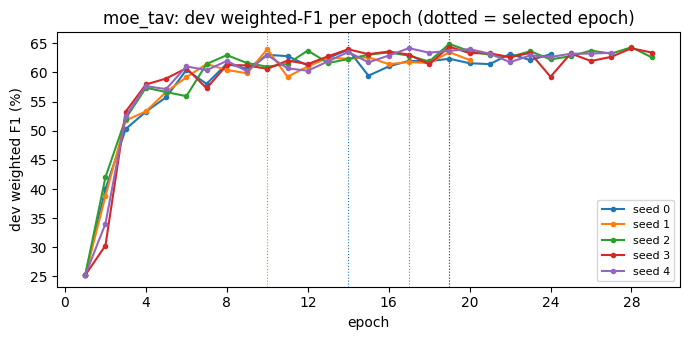

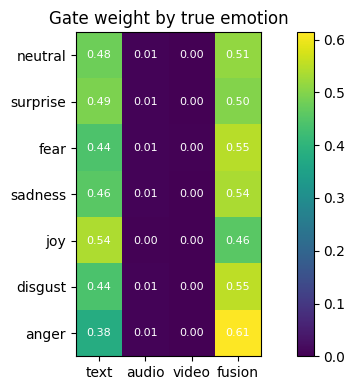

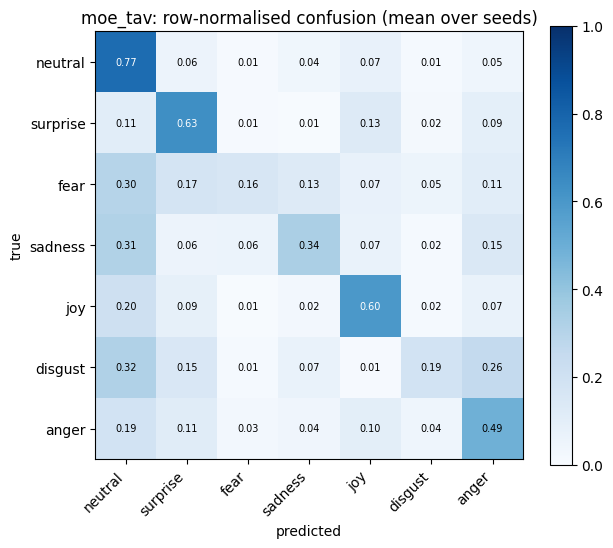

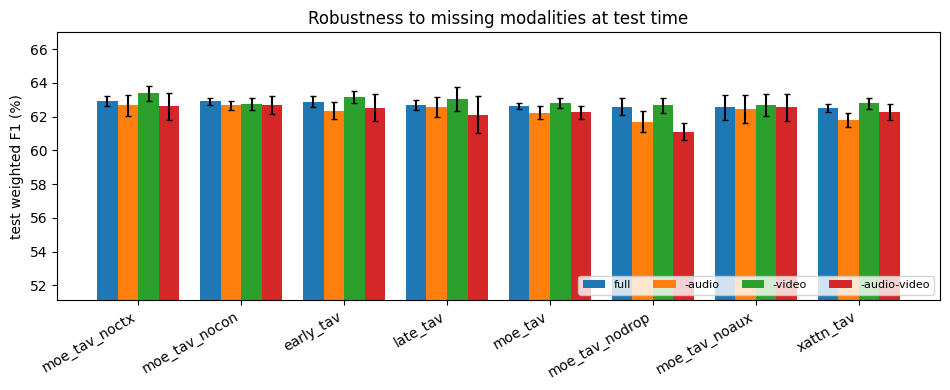

In [16]:
# gate weights, confusion matrix, error examples (main model) and robustness plot
figs = []
if main_preds and "gate" in main_preds[0]:
    experts = canon(runs[MAIN][0]["config"]["modalities"]) + ["fusion"]
    G = np.mean([m["gate"] for m in main_preds], 0).astype(np.float64)
    y = main_preds[0]["y"]
    gate_by_class = pd.DataFrame([G[y == c].mean(0) if (y == c).any() else np.zeros(len(experts)) for c in range(C)],
                                 index=EMOTIONS, columns=experts).round(3)
    gate_by_cond = pd.DataFrame({cond: np.mean([m["gate"].mean(0) for m in load_preds(MAIN, cond)], 0).astype(np.float64)
                                 for cond in runs[MAIN][0]["test"]}, index=experts).T.round(3)
    display(Markdown("### Mean gate weight per true emotion (main model)"), gate_by_class)
    display(Markdown("### Mean gate weight per test condition"), gate_by_cond)
    fig, ax = plt.subplots(figsize=(1.4 * len(experts) + 2, 4))
    im = ax.imshow(gate_by_class.values, cmap="viridis", vmin=0, vmax=max(0.5, gate_by_class.values.max()))
    ax.set_xticks(range(len(experts)), experts)
    ax.set_yticks(range(C), EMOTIONS)
    for i in range(C):
        for j in range(len(experts)):
            ax.text(j, i, f"{gate_by_class.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    fig.colorbar(im)
    ax.set_title("Gate weight by true emotion")
    figs.append((fig, "gate_by_class.png"))

if main_preds:
    cm = np.mean([np.bincount(m["y"] * C + m["pred"], minlength=C * C).reshape(C, C) /
                  np.bincount(m["y"] * C + m["pred"], minlength=C * C).reshape(C, C).sum(1, keepdims=True).clip(min=1)
                  for m in main_preds], 0)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(C), EMOTIONS, rotation=45, ha="right")
    ax.set_yticks(range(C), EMOTIONS)
    for i in range(C):
        for j in range(C):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="w" if cm[i, j] > 0.5 else "k", fontsize=7)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{MAIN}: row-normalised confusion (mean over seeds)")
    fig.colorbar(im)
    figs.append((fig, "confusion.png"))

    m0, man = main_preds[0], pd.read_csv(MANIFEST_PATH).set_index("uid")
    wrong = m0["pred"] != m0["y"]
    errors = pd.DataFrame({"uid": m0["uid"][wrong], "true": [EMOTIONS[i] for i in m0["y"][wrong]],
                           "pred": [EMOTIONS[i] for i in m0["pred"][wrong]],
                           "confidence": m0["probs"][wrong].max(1).astype(np.float64).round(3)})
    errors["speaker"] = man.loc[errors.uid, "speaker"].values
    errors["text"] = man.loc[errors.uid, "text"].values
    if "gate" in m0:
        for j, e in enumerate(experts):
            errors[f"gate_{e}"] = m0["gate"][wrong][:, j].astype(np.float64).round(3)
    errors = errors.sort_values("confidence", ascending=False)
    pairs = errors.groupby(["true", "pred"]).size().sort_values(ascending=False).head(8).rename("count").reset_index()
    display(Markdown("### Most frequent confusions (seed 0)"), pairs)
    display(Markdown(f"### Most confident errors (seed 0, {len(errors)} errors in total)"),
            errors.head(25).drop(columns="uid"))

rc = ["full", "-audio", "-video", "-audio-video"]
names = [n for n in order if all(c in runs[n][0]["test"] for c in rc)]
if names:
    fig, ax = plt.subplots(figsize=(max(7, 1.2 * len(names)), 4))
    w = 0.8 / len(rc)
    for k, c in enumerate(rc):
        vals = [[r["test"][c]["weighted_f1"] for r in runs[n]] for n in names]
        ax.bar(np.arange(len(names)) + k * w, [np.mean(v) for v in vals], w, yerr=[np.std(v) for v in vals],
               label=c, capsize=2)
    ax.set_xticks(np.arange(len(names)) + 0.4 - w / 2, names, rotation=30, ha="right")
    ax.set_ylabel("test weighted F1 (%)")
    lo = min(np.mean([r["test"][c]["weighted_f1"] for r in runs[n]]) for n in names for c in rc)
    ax.set_ylim(max(0, lo - 10), None)
    ax.legend(ncol=4, fontsize=8, loc="lower right")
    ax.set_title("Robustness to missing modalities at test time")
    figs.append((fig, "robustness.png"))

# learning curves of the main model (dev weighted-F1 per epoch, one line per seed)
fig, ax = plt.subplots(figsize=(7, 3.5))
for r in runs.get(MAIN, []):
    h = r["history"]
    line, = ax.plot([e["epoch"] for e in h], [e["dev_wf1"] for e in h], marker=".", label=f"seed {r['config']['seed']}")
    ax.axvline(r["best_epoch"], color=line.get_color(), ls=":", lw=0.8)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("epoch")
ax.set_ylabel("dev weighted F1 (%)")
ax.set_title(f"{MAIN}: dev weighted-F1 per epoch (dotted = selected epoch)")
ax.legend(fontsize=8)
figs.insert(0, (fig, "curves"))

for fig, _ in figs:
    fig.tight_layout()
    display(fig)
    plt.close(fig)